# Mini-projet Data Mining : détection automatique des crises d'absence à partir de signaux EEG

**Parties I à XII (Questions 1 à 14)**

Binôme : Mohamed Aziz Ncir, Souhail Mbarki · Enregistrement de démonstration : `230102B_F_0000` · Apprentissage : les 19 enregistrements annotés

Le code de traitement est regroupé dans le paquet `src/`, à la racine du projet ; ce notebook
appelle ces fonctions et commente les résultats.

| Module | Rôle | Parties |
| --- | --- | --- |
| `src/data.py` | lecture des fichiers MATLAB, des marqueurs, des annotations Excel | I, II |
| `src/preprocessing.py` | filtrage du signal (coupe-bande secteur, passe-bande 0,5–40 Hz) | I |
| `src/visualization.py` | figures (signal, montage, spectre, classes, fenêtres, FFT) | I à VI |
| `src/labeling.py` | colonne `Class` à partir des intervalles de crise | III |
| `src/windowing.py` | découpage en fenêtres de 2 s, recouvrement 50 % | IV |
| `src/features.py` | caractéristiques temporelles et puissances par bande (FFT) | V, VI |
| `src/exploration.py` | statistiques des crises, comparaison des classes, corrélations | II, VII |
| `src/training.py` | séparation 80/20, modèles, recherche d'hyperparamètres | VIII |
| `src/evaluation.py` | métriques, matrices de confusion, comparaisons | IX |
| `src/detection.py` | prédictions par enregistrement, fenêtres → intervalles de crise, comparaison aux annotations | X |
| `src/errors.py` | types d'erreurs (VP, FP, FN, VN) et où elles se trouvent | XI |
| `src/improvement.py` | seuil en validation interne, lissage, nouvelles variables, comparaison des variantes | XII |

Dépendances : `numpy`, `pandas`, `scipy`, `matplotlib`, `openpyxl`, `scikit-learn`
→ `pip install numpy pandas scipy matplotlib openpyxl scikit-learn`

Exécution complète : 15 minutes environ, dont 6 pour la recherche d'hyperparamètres (Question 12) et 5 pour les Parties X à XII.

## 0. Configuration

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Racine du projet : le dossier qui contient `src/` et `data/`.
CURRENT = Path.cwd().resolve()
ROOT = next(
    folder
    for folder in [CURRENT, *CURRENT.parents]
    if (folder / "src" / "data.py").is_file()
)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import (
    channel_quality,
    list_recordings,
    load_recording,
    load_seizure_annotations,
    match_recording_id,
    saturation_report,
    summarize,
)
from src.preprocessing import clean_recording, mains_frequency
from src import visualization as viz

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)
plt.rcParams["figure.dpi"] = 110

FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)


def save(name):
    """Enregistre la figure courante dans reports/figures puis l'affiche."""
    plt.tight_layout()
    plt.savefig(FIGURES / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()


print("Projet :", ROOT)

Projet : /home/claude/work/DataMining


### Enregistrements disponibles

Chaque enregistrement est fourni en deux fichiers : `...d.mat` contient le signal,
`...h.mat` contient les marqueurs posés par le manipulateur pendant l'examen.

In [2]:
display(list_recordings(ROOT))

,recording_id,data_file,header_file,size_mb
0,190304A_E_0000,190304A_E_0000d.mat,190304A_E_0000h.mat,50.55
1,191113A_D_0000,191113A_D_0000d.mat,191113A_D_0000h.mat,41.70
2,200625A_F_0000,200625A_F_0000d.mat,200625A_F_0000h.mat,27.56
3,210204B_C_0000,210204B_C_0000d.mat,210204B_C_0000h.mat,29.91
4,210208B_G_0000,210208B_G_0000d.mat,210208B_G_0000h.mat,26.68
5,210406A_F_0000,210406A_F_0000d.mat,210406A_F_0000h.mat,45.31
6,210427B_C_0000,210427B_C_0000d.mat,210427B_C_0000h.mat,28.31
7,210504B_C_0000,210504B_C_0000d.mat,210504B_C_0000h.mat,62.61
8,210914B_A_0000,210914B_A_0000d.mat,210914B_A_0000h.mat,23.31
9,210928B_B_0000,210928B_B_0000d.mat,210928B_B_0000h.mat,27.51


## Question 1 — Chargement du fichier et description des données

**Format des fichiers.** Les fichiers `.mat` ne contiennent pas une simple matrice mais un
`timetable` MATLAB, enregistré comme objet (système MCOS). `scipy.io.loadmat` ne sait pas
décoder ce type et renvoie un objet vide : les valeurs sont en réalité rangées dans la
variable cachée `__function_workspace__`, qui est elle-même un mini fichier MAT.

La fonction `load_recording` relit cet espace de travail, retrouve la structure du timetable
**par ses champs** (et non par une position fixe, qui changerait d'un fichier à l'autre),
puis reconstruit le signal :

1. le signal est stocké par blocs d'une seconde → on concatène les blocs de chaque canal ;
2. les instants (`rowTimes`) sont un `duration` MATLAB, donc exprimés en **millisecondes** ;
3. la fréquence d'échantillonnage se déduit de `nombre d'échantillons par bloc / durée du bloc`.

In [3]:
RECORDING_ID = "230102B_F_0000"

recording = load_recording(RECORDING_ID, ROOT)
recording

Recording(230102B_F_0000, 313600 echantillons, 21 canaux, 256 Hz, 1225 s)

### Tableau de synthèse

In [4]:
display(summarize(recording))

,Propriete,Valeur
0,Fichier de signal,230102B_F_0000d.mat
1,Fichier d'entete,230102B_F_0000h.mat
2,Nombre de lignes (echantillons),313 600
3,Nombre de variables (colonnes),22
4,dont canaux de mesure,21
5,dont canaux EEG,19
6,Canaux non EEG,"SLI, ECG"
7,Frequence d'echantillonnage,256.0 Hz
8,Periode d'echantillonnage,3.906 ms
9,Duree totale,1225.0 s (20 min 25.0 s)


**Réponses à la Question 1**

| Élément demandé | Valeur |
| --- | --- |
| Nombre de lignes | 313 600 échantillons |
| Nombre de variables | 22 colonnes = 1 colonne de temps + 21 canaux (19 EEG + SLI + ECG) |
| Fréquence d'échantillonnage | 256 Hz (période de 3,906 ms) |
| Durée totale | 1 225 s, soit 20 min 25 s |
| Valeurs manquantes | 0 (aucun NaN, aucune valeur infinie) |

*Unités* : le temps est en secondes ; l'unité d'amplitude n'est **pas** enregistrée dans le
fichier (le champ `varUnits` du timetable est vide). Le microvolt est la convention en EEG,
et l'ordre de grandeur du signal filtré (quelques dizaines de µV, voir Question 2) le confirme.

### Premières lignes du fichier

In [5]:
display(recording.data.head().round(2))

,Time,EEGFp1,EEGFp2,EEGF7,EEGF3,EEGFz,EEGF4,EEGF8,EEGT4,EEGC4,EEGCz,EEGC3,EEGT3,EEGT5,EEGP3,EEGPz,EEGP4,EEGT6,EEGO2,EEGO1,SLI,ECG
0,0.00,519.16,809.65,631.20,-19.42,2631.40,1.34,818.96,8.32,407.11,677.20,-131.11,358.96,92.98,678.81,246.74,181.94,-165.12,135.23,329.43,0.09,3126.66
1,0.00,329.79,591.29,443.80,-208.07,2528.66,-198.59,594.51,-169.59,187.85,479.42,-311.71,169.95,-96.74,488.73,40.00,-104.44,-350.55,-51.64,152.95,0.09,3309.94
2,0.01,199.84,466.35,312.07,-339.09,2381.17,-329.61,466.71,-299.00,39.82,351.26,-440.58,41.97,-230.27,358.42,-91.55,-242.98,-476.91,-178.36,15.84,0.09,3449.91
3,0.01,298.64,601.13,412.30,-237.79,2620.66,-219.53,607.40,-205.03,161.18,462.77,-344.11,146.32,-128.42,461.88,24.25,-48.24,-373.82,-75.09,103.90,0.09,3377.78
4,0.02,497.86,818.96,617.96,-32.49,2880.37,-9.04,835.07,-3.13,401.74,675.23,-139.16,353.95,82.60,670.94,242.80,234.21,-166.19,134.33,310.28,0.09,3196.64


### Contrôle de qualité canal par canal

Aucune valeur manquante, mais trois remarques utiles pour la suite :

* les amplitudes brutes atteignent plusieurs milliers d'unités, très au-dessus d'un EEG
  physiologique : il s'agit d'artefacts et d'une composante continue ;
* les canaux `SLI` (stimulation lumineuse) et `ECG` ne sont pas de l'EEG et seront exclus
  de l'extraction de caractéristiques ;
* « zéro valeur manquante » ne veut pas dire « zéro valeur inutilisable » : certains
  échantillons sont **saturés**, c'est-à-dire collés à la butée du convertisseur.

In [6]:
display(channel_quality(recording))

,canal,type,manquantes,infinies,min,max,moyenne,ecart_type
0,EEGFp1,EEG,0,0,-2781.03,5823.30,253.29,218.04
1,EEGFp2,EEG,0,0,-2508.79,5815.42,513.78,215.43
2,EEGF7,EEG,0,0,-2737.36,5818.82,361.76,217.37
3,EEGF3,EEG,0,0,-3344.13,5862.67,-214.44,217.35
4,EEGFz,EEG,0,0,-5865.00,5865.00,46.85,1450.09
5,EEGF4,EEG,0,0,-3339.83,5858.91,-211.87,219.58
6,EEGF8,EEG,0,0,-2560.70,5825.44,521.82,222.44
7,EEGT4,EEG,0,0,-3325.33,5865.00,-198.92,220.46
8,EEGC4,EEG,0,0,-3251.95,5843.52,173.06,235.70
9,EEGCz,EEG,0,0,-2698.70,5811.84,420.53,282.36


Le tableau suivant compte ces échantillons saturés. Le résultat rejoint les marqueurs de
l'entête, qui signalent explicitement « SATURATION DES VOIES : Fz / ECG » :
l'ECG et le canal `Fz` sont les plus touchés, et le canal `SLI` est constant sur tout
l'enregistrement (aucune information). Ces trois canaux seront écartés des caractéristiques.

In [7]:
display(saturation_report(recording).head(8))

,canal,maximum_absolu,echantillons_satures,pourcentage,ecart_type,remarque
0,ECG,5865.0,2428,0.774,1236.5,saturation
1,EEGFz,5865.0,57,0.018,1450.1,saturation
2,EEGT4,5865.0,2,0.001,220.5,saturation
3,EEGF3,5862.7,1,0.000,217.4,
4,EEGPz,5865.0,1,0.000,238.7,
5,EEGP4,5865.0,1,0.000,248.5,
6,EEGT6,5865.0,1,0.000,225.9,
7,EEGC3,5861.4,1,0.000,223.5,


### Marqueurs de l'examen (fichier `*h.mat`)

Le fichier d'entête contient les événements notés pendant l'enregistrement : début de
l'examen, yeux ouverts (`YO`) / yeux fermés (`YF`), hyperpnée (`HPN`, 3 minutes),
stimulation lumineuse intermittente (`SLI=3Hz` à `SLI=25Hz`) et saturations de voies.
Ces manœuvres sont précisément celles qui provoquent les absences : elles aident à lire
le tracé, même si elles ne remplacent pas les annotations de crises.

In [8]:
display(recording.events)

,onset_s,label,duration_s
0,0.007812,Début,NaN
1,4.375000,SATURATION DES VOIES : Fz ECG,NaN
2,9.375000,SATURATION DES VOIES : Fz,NaN
3,19.375000,SATURATION DES VOIES : Fz ECG,NaN
4,69.375000,SATURATION DES VOIES : ECG,NaN
5,157.625000,YO,NaN
6,176.375000,YF,NaN
7,179.937500,HPN 3mn début,NaN
8,199.718750,HPN - 00:00:20,NaN
9,219.562500,HPN - 00:00:40,NaN


## Question 2 — Représentation du signal EEG en fonction du temps

### 2.1 Signal brut

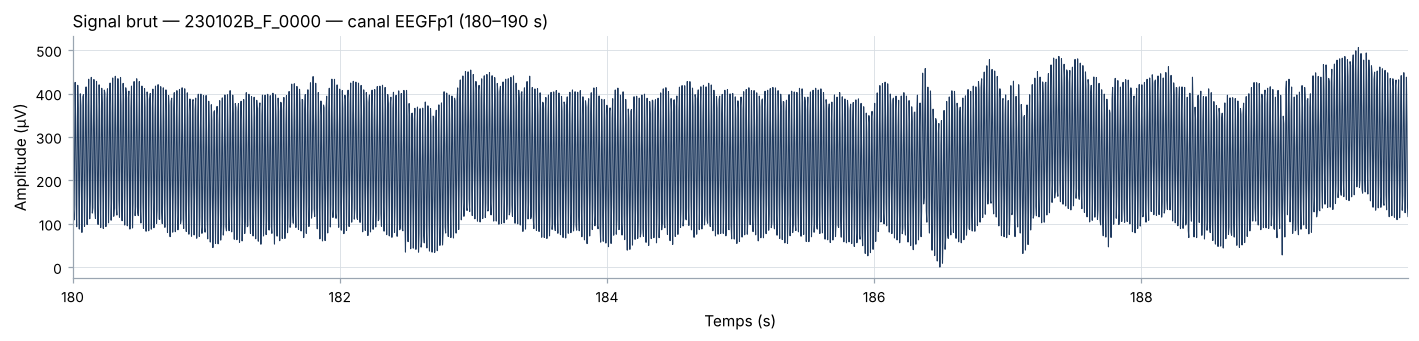

In [9]:
ax = viz.plot_signal(
    recording,
    channel="EEGFp1",
    start=180,
    end=190,
    title=f"Signal brut — {RECORDING_ID} — canal EEGFp1 (180–190 s)",
)
save("q2_1_signal_brut")

Le tracé brut est illisible : une oscillation très rapide sature la figure et le signal
oscille autour de +250 µV au lieu de zéro. Le spectre ci-dessous donne l'explication.

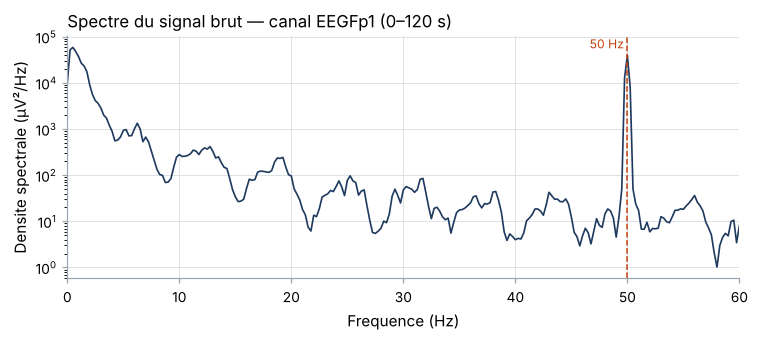

In [10]:
ax = viz.plot_spectrum(
    recording,
    channel="EEGFp1",
    start=0,
    end=120,
    title="Spectre du signal brut — canal EEGFp1 (0–120 s)",
)
save("q2_2_spectre_brut")

La raie à **50 Hz** (réseau électrique) domine tout le spectre, et une dérive très lente
ajoute la composante continue. Deux filtres suffisent à rendre le signal exploitable :

* un **coupe-bande** (notch) à 50 Hz ;
* un **passe-bande 0,5–40 Hz**, qui est la bande utile de l'EEG et contient les rythmes
  Delta, Theta, Alpha et Beta étudiés en Partie VI.

Les deux filtres sont appliqués en aller-retour (`filtfilt`) pour ne pas décaler le signal
dans le temps : une crise reste ainsi au bon endroit sur l'axe des temps.

In [11]:
print("Fréquence du secteur détectée :", mains_frequency(
    recording.channel("EEGFp1"), recording.sampling_rate), "Hz")

clean = clean_recording(recording)
print("Prétraitement appliqué :", clean.source["preprocessing"])

Fréquence du secteur détectée : 50.0 Hz


Prétraitement appliqué : notch 50 Hz + passe-bande 0.5-40.0 Hz


### 2.2 Signal filtré — même fenêtre de 10 secondes

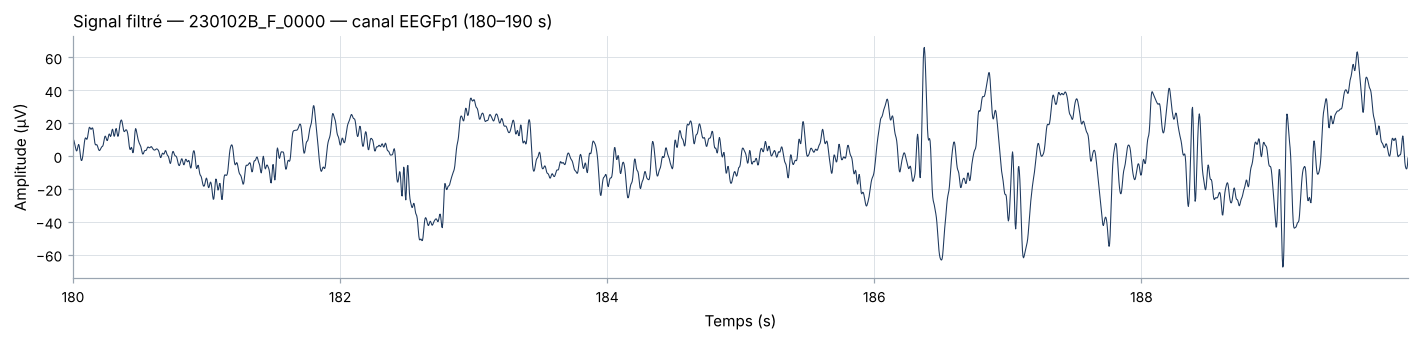

In [12]:
ax = viz.plot_signal(
    clean,
    channel="EEGFp1",
    start=180,
    end=190,
    title=f"Signal filtré — {RECORDING_ID} — canal EEGFp1 (180–190 s)",
)
save("q2_3_signal_filtre")

L'activité cérébrale apparaît : amplitude de ±50 µV environ, ce qui correspond bien à un
EEG de surface exprimé en microvolts.

### 2.3 Vue d'ensemble de l'enregistrement

L'axe vertical est cadré sur 99,5 % des valeurs, sinon quelques artefacts de plusieurs
centaines de microvolts écraseraient le reste du tracé. Les traits verticaux sont les
marqueurs de l'examen.

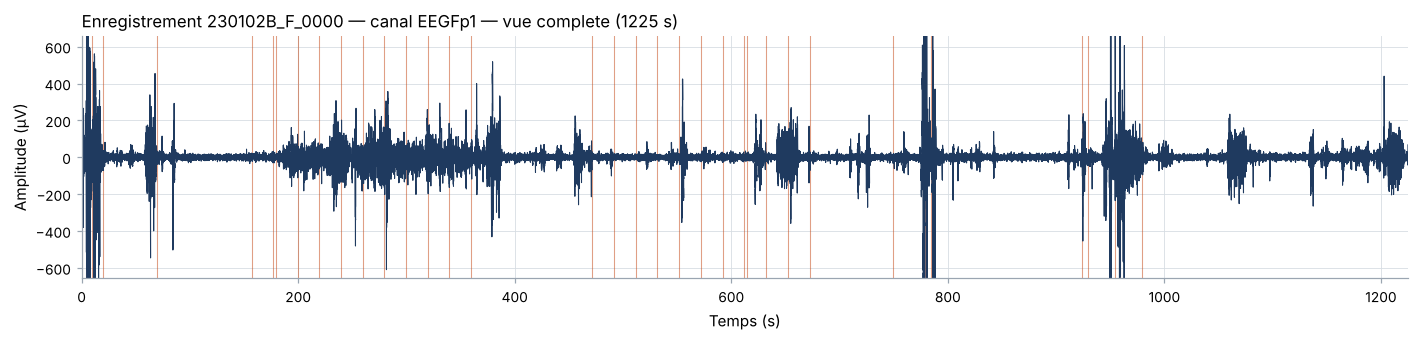

In [13]:
ax = viz.plot_overview(clean, channel="EEGFp1")
save("q2_4_vue_complete")

### 2.4 Montage multi-canaux

Affichage de type clinique : les 19 canaux EEG empilés, chacun centré sur sa moyenne.

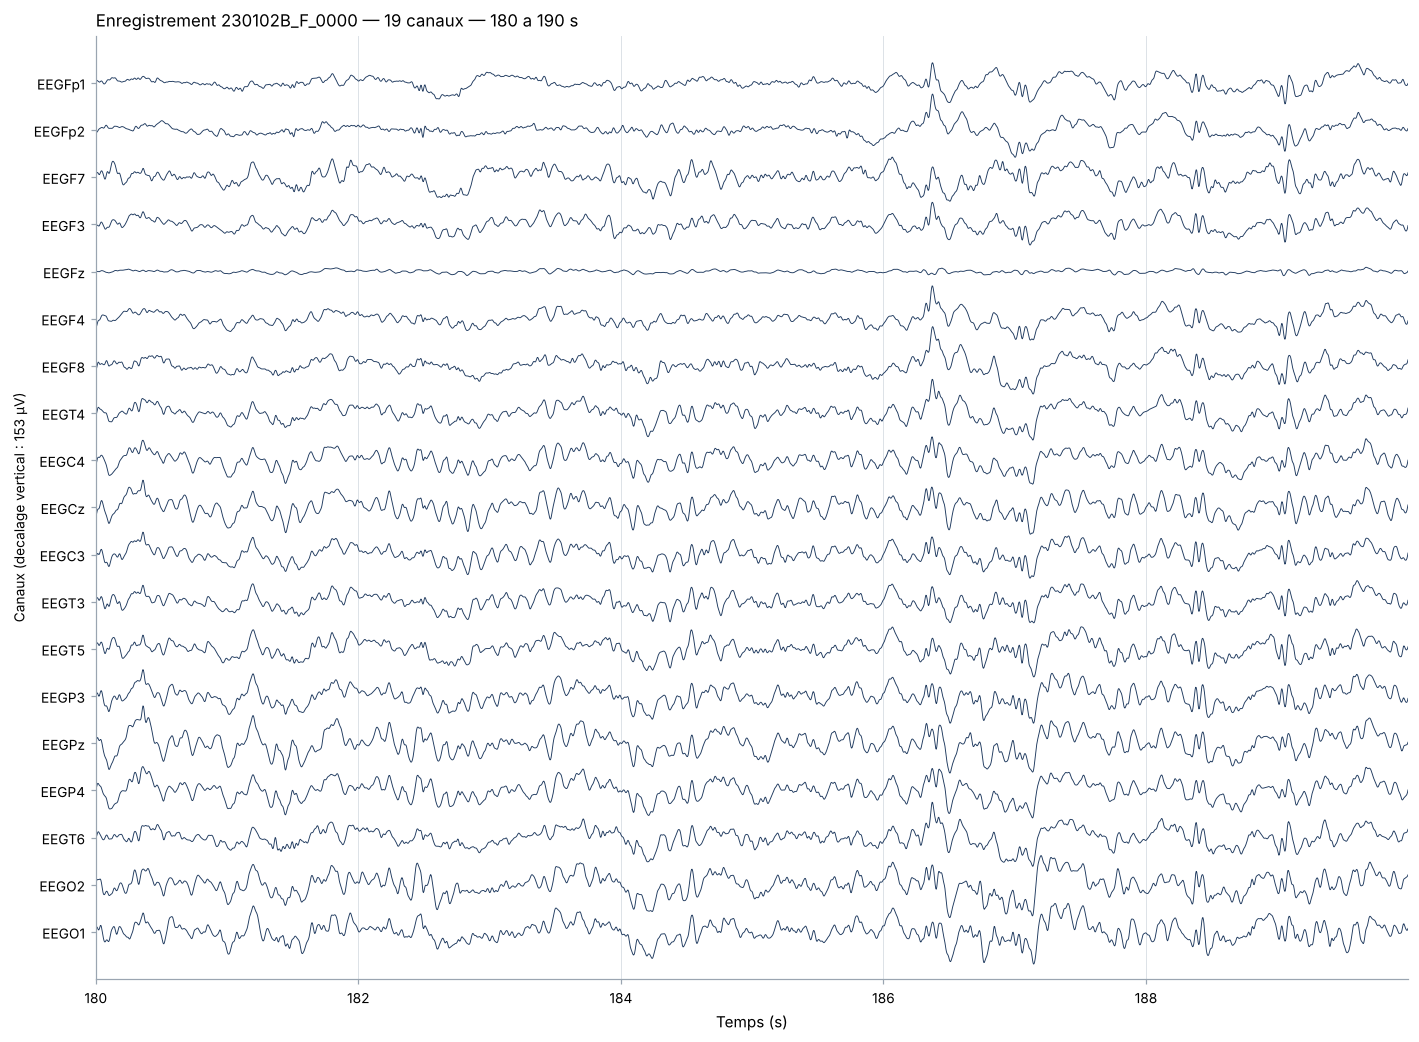

In [14]:
ax = viz.plot_montage(clean, start=180, end=190)
save("q2_5_montage_repos")

## Question — Que remarque-t-on visuellement pendant les crises ?

L'épisode ci-dessous (vers 277–283 s, pendant l'hyperpnée) montre le motif recherché.

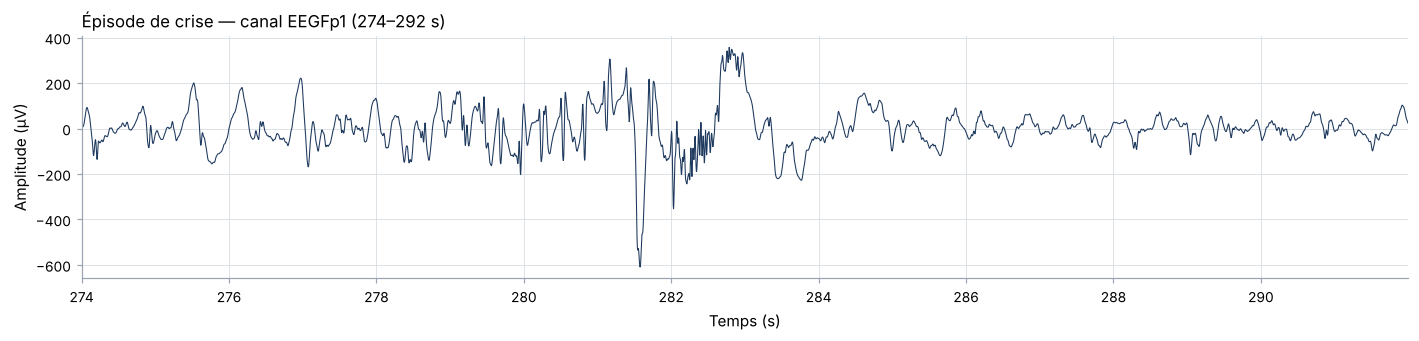

In [15]:
ax = viz.plot_signal(
    clean,
    channel="EEGFp1",
    start=274,
    end=292,
    title="Épisode de crise — canal EEGFp1 (274–292 s)",
)
save("q2_6_crise_zoom")

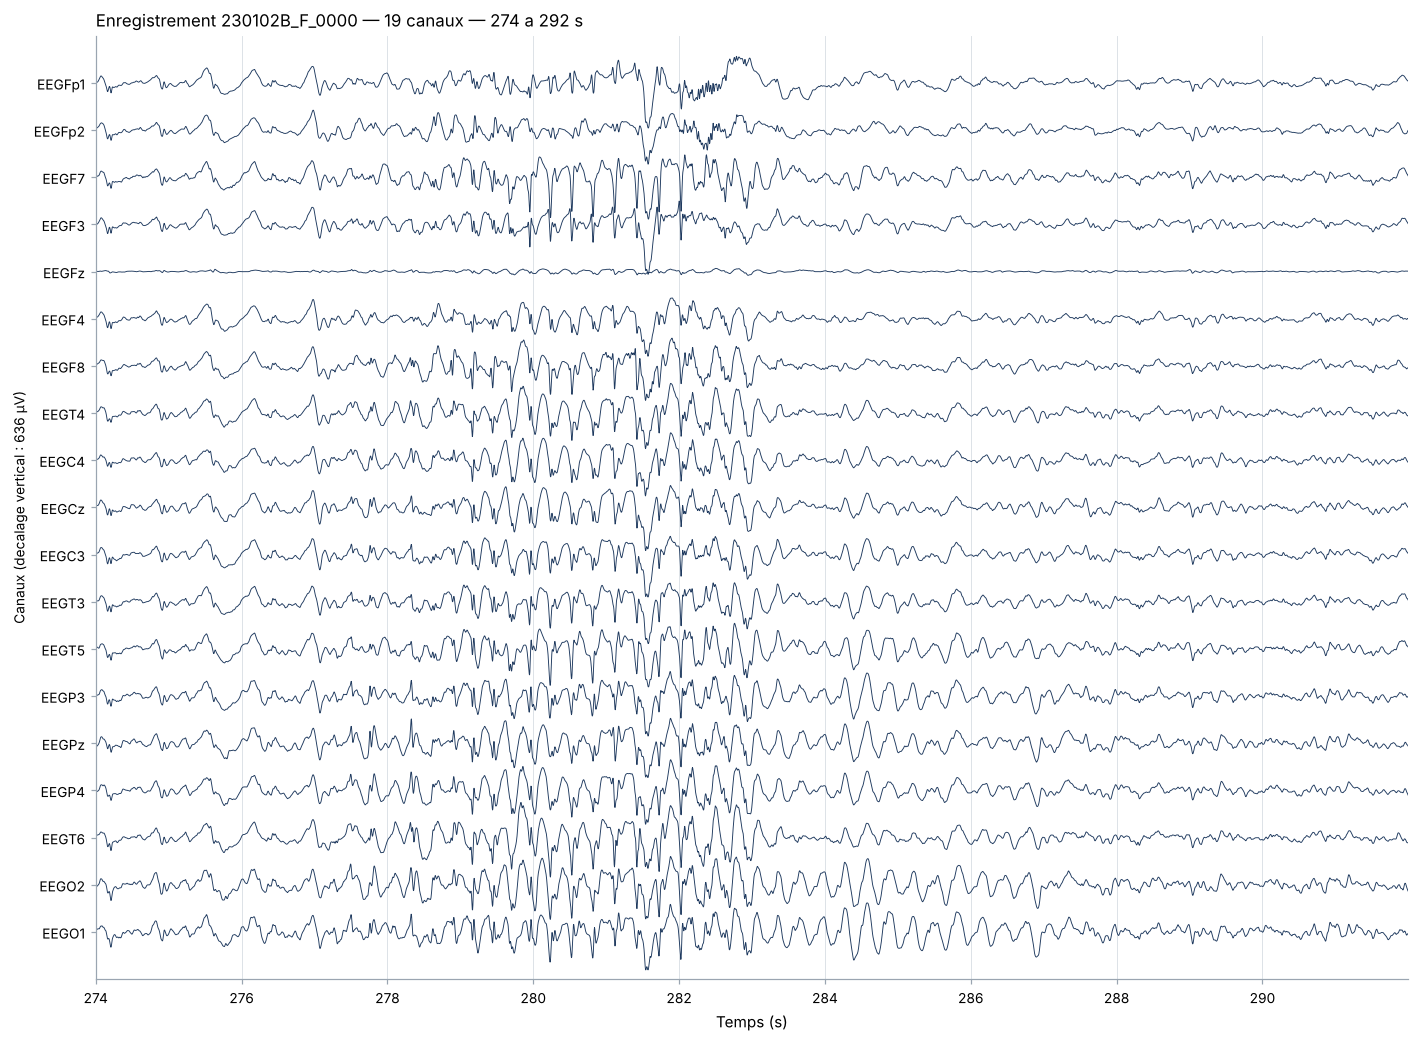

In [16]:
ax = viz.plot_montage(clean, start=274, end=292)
save("q2_7_crise_montage")

**Observations**

1. **Amplitude** : elle est multipliée par 3 à 5 pendant l'épisode (±200 µV contre ±50 µV
   hors crise). C'est ce que mesureront l'écart-type, l'amplitude crête à crête, le RMS et
   l'énergie de la Partie V.
2. **Rythme** : le tracé devient très régulier, autour de 3 cycles par seconde
   (pointe-onde à 3 Hz, motif caractéristique de l'absence). Hors crise le tracé est
   irrégulier et plus rapide. La puissance Delta/Theta de la Partie VI devrait donc bien
   séparer les deux classes.
3. **Généralisation** : le motif apparaît en même temps sur *tous* les canaux, alors que les
   artefacts (clignements, mouvements) ne touchent que quelques électrodes.
4. **Début et fin nets** : l'épisode démarre et s'arrête brutalement, ce qui justifie de
   découper le signal en fenêtres de 2 s (Partie IV) plutôt que de travailler échantillon
   par échantillon.

## Partie II : Exploitation des annotations

### Le nouveau fichier d'annotations

Le fichier `Annotations_MAJ.xlsx`, envoyé par l'encadrante le 1er octobre, ajoute la colonne
**`DebutTrace`** : l'heure de début de l'enregistrement. Le point bloquant de la Partie I est
donc réglé. Les valeurs `DebCE` et `FinCE` sont des **heures de la journée** (dans Excel, une
heure est stockée comme une fraction de journée : `0,5` = midi). On en déduit :

| Grandeur | Calcul |
| --- | --- |
| début de la crise, en secondes depuis le début du tracé | `DebCEk − DebutTrace` |
| fin de la crise, en secondes depuis le début du tracé | `FinCEk − DebutTrace` |
| durée de la crise | `FinCEk − DebCEk` |

Exemple donné par l'encadrante pour `190304A-E` : tracé démarré à 10:13:35, crise de 10:35:06
à 10:35:13, donc une durée de **7 s**, et un début à 21 min 31 s = **1 291 s** du début du tracé.
La cellule suivante retrouve exactement ces valeurs.

In [17]:
from src.data import annotation_issues, file_id, ANNOTATIONS_FILE
from src.labeling import seizure_intervals, label_samples, add_class_column, class_balance
from src.windowing import make_windows, window_parameters
from src.features import (EEG_CHANNELS, BANDS, FEATURES, TEMPORAL_FEATURES,
                          window_features, build_dataset)
from src.exploration import (seizure_table, seizure_statistics, plot_seizure_durations,
                             class_comparison, plot_class_means, plot_class_boxplots,
                             correlated_pairs, plot_correlation)
import numpy as np

annotations = load_seizure_annotations(ROOT)   # lit Annotations_MAJ.xlsx
print("Fichier lu :", ANNOTATIONS_FILE)
print("Crises :", len(annotations), "| enregistrements annotés :", annotations["recording_id"].nunique())
display(annotations[annotations["recording_id"] == "190304A-E"])

Fichier lu : Annotations_MAJ.xlsx
Crises : 83 | enregistrements annotés : 19


,recording_id,seizure,trace_start,start_clock,end_clock,start_s,end_s,reported_count,duration_s
0,190304A-E,1,10:13:35,10:35:06,10:35:13,1291.0,1298.0,1,7.0


### Contrôle qualité du fichier

Avant de s'en servir, on vérifie le fichier. Les contrôles automatiques (doublons, durées
impossibles, crises hors du tracé, nombre de crises annoncé) relèvent les points suivants.

In [18]:
# Durée de chaque enregistrement annoté, pour vérifier que les crises tiennent dans le tracé
available = {rid: rid for rid in list_recordings(ROOT)["recording_id"]}
annotated = [file_id(e) for e in sorted(annotations["recording_id"].unique()) if file_id(e) in available]

recording_info = {}
for rid in annotated:
    rec = load_recording(rid, ROOT, with_events=False)
    recording_info[match_recording_id(rid)] = {"n_samples": rec.n_samples, "duration_s": rec.duration,
                                               "fs": rec.sampling_rate}
del rec

issues = annotation_issues(ROOT, durations={k: v["duration_s"] for k, v in recording_info.items()})
display(issues)

no_annotation = sorted(set(available) - set(annotated))
print("Enregistrements sans annotation (exclus, classe inconnue) :", no_annotation)

,enregistrement,probleme,decision
0,230406B-A,"present 2 fois (lignes Excel 11 et 19), ecart ...",premiere ligne gardee (identique a l'ancien fi...
1,230515B-G,"present 2 fois (lignes Excel 12 et 20), ecart ...",premiere ligne gardee (identique a l'ancien fi...
2,210504B-C,"FinCE1 = 0,785486 donne une crise de 6 h ; l'a...",FinCE1 corrige : 0.785486 -> 0.535486
3,210914B-A,NombreCE = 6 mais 11 intervalles remplis,les intervalles remplis font foi


Enregistrements sans annotation (exclus, classe inconnue) : ['200625A_F_0000', '210204B_C_0000', '210208B_G_0000']


**Décisions prises**

| Point relevé | Décision | Justification |
| --- | --- | --- |
| `230406B-A` et `230515B-G` apparaissent deux fois, avec des heures qui diffèrent de 6 à 11 s | on garde la **première** ligne | c'est celle de l'ancien fichier `Crises absences.xlsx` |
| `210504B-C`, crise 1 : `FinCE1 = 0,785486`, soit une crise de **6 heures** | corrigé en `0,535486` (8 s) | faute de frappe (7 au lieu de 5) : l'ancien fichier donne `0,535486` |
| `210914B-A` : `NombreCE = 6` mais 11 intervalles remplis | les 11 intervalles sont gardés | ce sont des absences « atypiques » (colonne `TypeAbs`) ; le signal confirme chaque intervalle (voir le contrôle après la Question 8) |
| `200625A_F`, `210204B_C`, `210208B_G` sont dans `data/raw` mais pas dans le fichier | exclus de l'apprentissage | sans `DebutTrace` ni intervalles, on ne connaît pas la classe des fenêtres |

Aucune crise ne dépasse la fin de son tracé et aucune fin n'est avant son début.
On garde donc **19 enregistrements** et **83 crises**.

**Validation de la Partie I.** Sur `230102B_F`, nous avions estimé l'origine des temps à
43 492,75 s (12:04:52,75) en cherchant les bouffées pointe-onde. La colonne `DebutTrace`
donne 12:04:53, soit 43 493 s : un écart de **0,25 s**. La méthode de la Partie I était donc
juste, et les nouvelles annotations tombent bien sur les crises visibles :

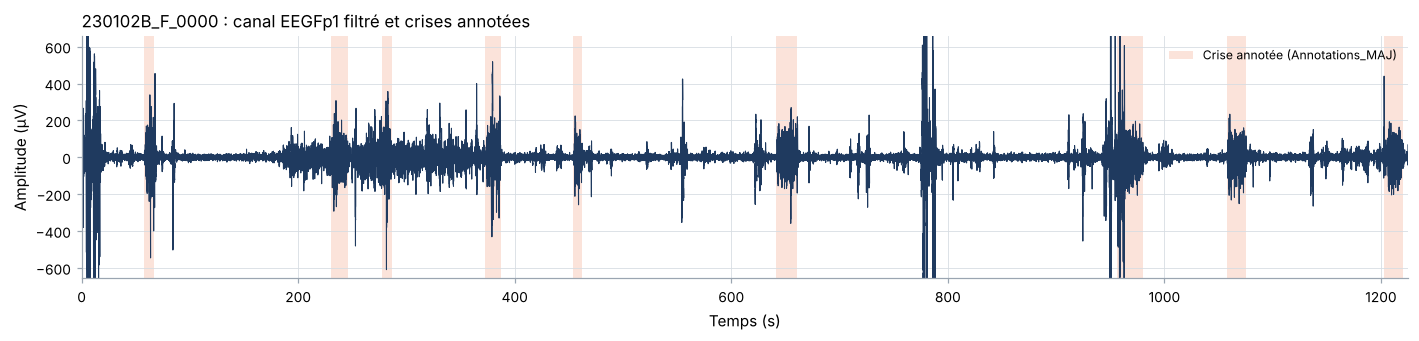

In [19]:
intervals = seizure_intervals(annotations, RECORDING_ID)

ax = viz.plot_overview(clean, channel="EEGFp1", show_events=False)
viz.shade_intervals(ax, intervals, label="Crise annotée (Annotations_MAJ)")
ax.legend(loc="upper right", fontsize=8, frameon=False)
ax.set_title(f"{RECORDING_ID} : canal EEGFp1 filtré et crises annotées", fontsize=11, loc="left")
save("q3_1_crises_annotees")

Chaque zone orange recouvre une bouffée de grande amplitude. Le contrôle est fait sur
**toutes** les crises de tous les enregistrements après la Question 8.

### Question 3 : début, fin et nombre de crises

Tableau demandé pour l'enregistrement étudié :

In [20]:
table_q3 = seizure_table(annotations, match_recording_id(RECORDING_ID))
display(table_q3)
print(f"Nombre total de crises dans {RECORDING_ID} : {len(table_q3)}")

,Debut (heure),Fin (heure),Debut (s),Fin (s),Duree (s)
Crise,,,,,
1,12:05:51,12:06:00,58.0,67.0,9.0
2,12:08:43,12:08:59,230.0,246.0,16.0
3,12:09:30,12:09:40,277.0,287.0,10.0
4,12:11:06,12:11:20,373.0,387.0,14.0
5,12:12:27,12:12:35,454.0,462.0,8.0
6,12:15:34,12:15:54,641.0,661.0,20.0
7,12:20:49,12:21:13,956.0,980.0,24.0
8,12:22:31,12:22:48,1058.0,1075.0,17.0
9,12:24:56,12:25:13,1203.0,1220.0,17.0


Nombre total de crises dans 230102B_F_0000 : 9


Les mêmes informations sont extraites automatiquement pour les 19 enregistrements
(une ligne par crise dans `annotations`). Nombre de crises par enregistrement :

In [21]:
counts = annotations.groupby("recording_id").size().rename("crises")
display(counts.to_frame().T)
print("Nombre total de crises (19 enregistrements) :", counts.sum())

recording_id,190304A-E,191113A-D,210406A-F,210427B-C,210504B-C,210914B-A,210928B-B,211027B-C,211104B-D,220106A-A,220121B-D,230102B-F,230105B-H,230210B-D,230224B-B,230406B-A,230515B-G,230519A-E,230718A-A
crises,1,2,1,1,12,11,2,8,5,2,3,9,7,1,3,4,2,2,7


Nombre total de crises (19 enregistrements) : 83


### Question 4 : durées et intervalles

L'**intervalle entre deux crises** est mesuré de la fin d'une crise au début de la suivante
(temps sans crise). Il n'existe que pour les enregistrements qui ont au moins deux crises.

In [22]:
stats = seizure_statistics(annotations)
display(stats)

demo = stats.loc[match_recording_id(RECORDING_ID)]
print(f"{RECORDING_ID} : durée moyenne {demo['duree moyenne (s)']} s, min {demo['duree min (s)']} s, "
      f"max {demo['duree max (s)']} s, intervalle moyen {demo['intervalle moyen (s)']} s")
d = annotations["duration_s"]
print(f"Toutes les crises : moyenne {d.mean():.1f} s, médiane {d.median():.0f} s, "
      f"écart-type {d.std():.1f} s, coefficient de variation {d.std() / d.mean():.0%}")

,crises,duree moyenne (s),duree min (s),duree max (s),intervalle moyen (s)
enregistrement,,,,,
190304A-E,1,7.0,7.0,7.0,NaN
191113A-D,2,9.0,5.0,13.0,161.0
210406A-F,1,8.0,8.0,8.0,NaN
210427B-C,1,18.0,18.0,18.0,NaN
210504B-C,12,11.2,2.0,60.0,211.3
210914B-A,11,16.0,4.0,49.0,84.8
210928B-B,2,27.5,25.0,30.0,108.0
211027B-C,8,15.4,8.0,47.0,130.3
211104B-D,5,8.0,6.0,10.0,152.8


230102B_F_0000 : durée moyenne 15.0 s, min 8.0 s, max 24.0 s, intervalle moyen 128.4 s
Toutes les crises : moyenne 13.3 s, médiane 11 s, écart-type 10.4 s, coefficient de variation 78%


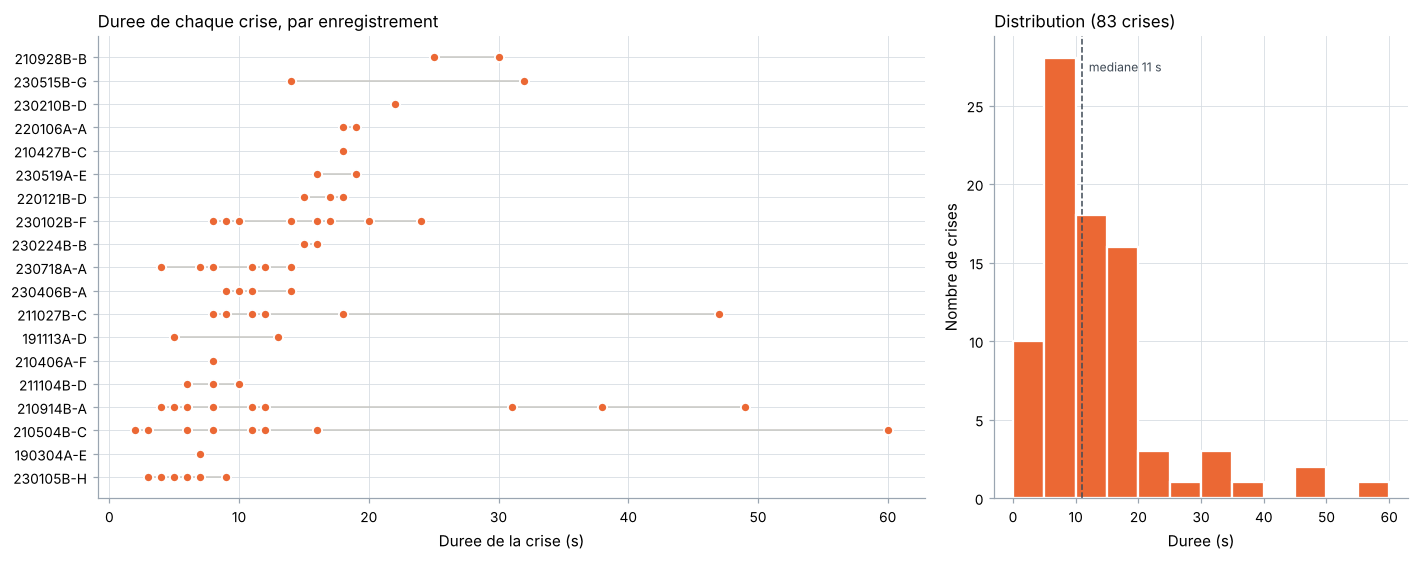

In [23]:
fig = plot_seizure_durations(annotations)
save("q4_1_durees_crises")

**Les crises ont-elles toutes une durée similaire ? Non.**

* Sur `230102B_F`, les 9 crises durent de 8 à 24 s (moyenne 15 s) : déjà un facteur 3.
* Sur l'ensemble, les durées vont de **2 s à 60 s** (moyenne 13,3 s, médiane 11 s).
  L'écart-type (10,4 s) vaut 78 % de la moyenne : la dispersion est forte.
* La durée dépend d'abord du **patient** : `230105B-H` fait des crises de 3 à 9 s,
  `210928B-B` de 25 à 30 s. À l'intérieur d'un même enregistrement, les durées restent
  souvent proches (ex. `230224B-B` : 15 à 16 s), sauf pour les absences atypiques de `210914B-A` (4 à 49 s).
* Les intervalles varient encore plus : de 52 s à 13 min en moyenne selon le patient.

Conséquence pour la suite : avec des fenêtres de 2 s, une crise de 2 à 3 s ne donne qu'une ou
deux fenêtres « crise ». Ces crises très courtes seront les plus difficiles à détecter.

## Partie III : Construction de la variable cible

### Question 5 : colonne `Class`

Pour chaque échantillon, `Class = 1` si son instant `t` vérifie `début ≤ t ≤ fin` pour une
crise annotée, sinon `Class = 0`. On l'ajoute au signal filtré de `230102B_F`.

In [24]:
labeled = add_class_column(clean, intervals)

print("Colonnes :", list(labeled.columns[:3]), "...", list(labeled.columns[-3:]))
# Passage de la classe 0 à la classe 1 au début de la crise 1 (58 s)
display(labeled.loc[labeled["Time"].between(57.98, 58.02), ["Time", "EEGFp1", "EEGF3", "Class"]].round(2))

Colonnes : ['Time', 'EEGFp1', 'EEGFp2'] ... ['SLI', 'ECG', 'Class']


,Time,EEGFp1,EEGF3,Class
14843,57.98,-1.23,6.02,0
14844,57.98,0.07,6.42,0
14845,57.99,1.47,5.38,0
14846,57.99,2.68,3.75,0
14847,58.00,3.56,2.36,0
14848,58.00,4.13,1.54,1
14849,58.00,4.49,1.12,1
14850,58.01,4.83,0.76,1
14851,58.01,5.41,0.13,1
14852,58.02,6.42,-1.03,1


### Question 6 : visualisation des deux classes

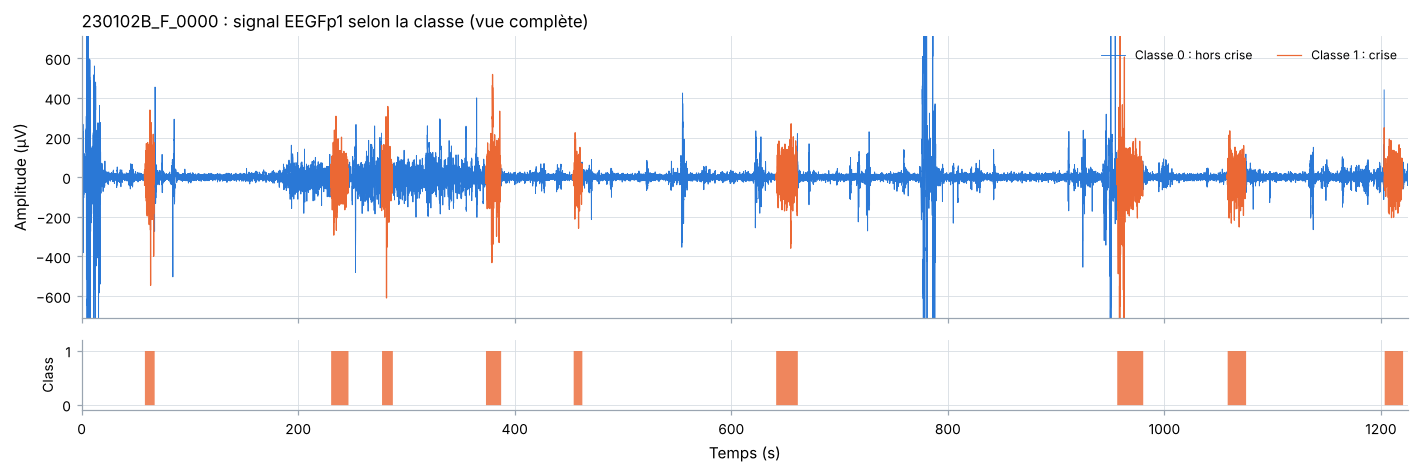

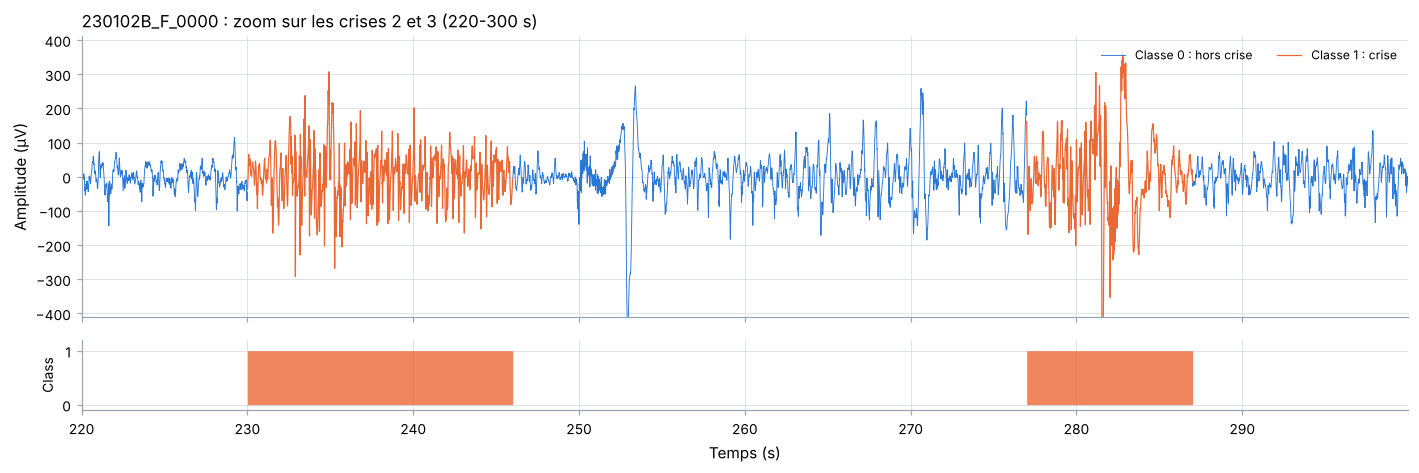

In [25]:
fig = viz.plot_class_signal(clean, labeled["Class"].to_numpy(), "EEGFp1",
                            title=f"{RECORDING_ID} : signal EEGFp1 selon la classe (vue complète)")
save("q6_1_classes_vue_complete")

fig = viz.plot_class_signal(clean, labeled["Class"].to_numpy(), "EEGFp1", start=220, end=300,
                            title=f"{RECORDING_ID} : zoom sur les crises 2 et 3 (220-300 s)")
save("q6_2_classes_zoom")

Le signal est orange pendant les crises : on retrouve les bouffées régulières de grande
amplitude décrites à la Question 2. Le bandeau du bas est la colonne `Class`.

**Le déséquilibre entre les deux classes est-il important ?**

In [26]:
print(f"Enregistrement {RECORDING_ID} :")
display(class_balance(labeled["Class"]))

# Même calcul sur les 19 enregistrements (sans recharger les signaux)
all_labels = []
for excel_id, info in recording_info.items():
    time = np.arange(info["n_samples"]) / info["fs"]
    all_labels.append(label_samples(time, seizure_intervals(annotations, excel_id)))
all_labels = np.concatenate(all_labels)

print(f"Les 19 enregistrements ({all_labels.size} échantillons, soit {all_labels.size / 256 / 3600:.1f} h de signal) :")
display(class_balance(all_labels))

Enregistrement 230102B_F_0000 :


,classe,effectif,pourcentage
0,0 - hors crise,279031,88.98
1,1 - crise,34569,11.02


Les 19 enregistrements (7427328 échantillons, soit 8.1 h de signal) :


,classe,effectif,pourcentage
0,0 - hors crise,7145645,96.21
1,1 - crise,281683,3.79


**Oui, le déséquilibre est très important.** Sur `230102B_F`, environ 11 % des échantillons sont
en crise, et ce patient en fait beaucoup. Sur l'ensemble des 19 enregistrements, seuls
**3,8 %** des échantillons sont en crise, contre 96,2 % hors crise (environ 1 pour 25).

Conséquences pour la suite :

* un modèle qui répond toujours « pas de crise » aurait déjà environ 96 % d'accuracy :
  l'accuracy seule ne suffit pas pour juger un modèle (thème de la Question 13) ;
* la séparation entraînement/test doit être **stratifiée** pour garder ces 4 % dans chaque jeu ;
* les hyperparamètres seront choisis sur le **F1-score** de la classe crise, pas sur l'accuracy.

## Partie IV : Segmentation du signal

### Question 7 : découpage en fenêtres

| Paramètre | Valeur |
| --- | --- |
| taille d'une fenêtre | 2 s × 256 Hz = **512 échantillons** |
| recouvrement | 50 %, donc un pas de **256 échantillons** (une nouvelle fenêtre par seconde) |
| nombre de fenêtres | ⌊(N − 512) / 256⌋ + 1 |
| classe d'une fenêtre | **1** si au moins 50 % de ses échantillons sont en crise, sinon **0** |

Le découpage utilise une *vue* sur le tableau du signal (`sliding_window_view`) : aucune copie
en mémoire, même pour un enregistrement d'une heure.

In [27]:
fs = clean.sampling_rate
size, step = window_parameters(fs, window_s=2.0, overlap=0.5)
print(f"Taille : {size} échantillons, pas : {step} échantillons")

windows = make_windows(clean.data[EEG_CHANNELS].to_numpy(), labeled["Class"].to_numpy(), fs, EEG_CHANNELS)
expected = (clean.n_samples - size) // step + 1
print(f"Tableau des fenêtres : {windows.data.shape}  (fenêtres, échantillons, canaux)")
print(f"Nombre de fenêtres : {len(windows)} (formule : {expected})")

# Fenêtres autour du début de la crise 1 (58 s)
display(windows.info[windows.info["start_s"].between(54, 60)])

Taille : 512 échantillons, pas : 256 échantillons
Tableau des fenêtres : (1224, 512, 19)  (fenêtres, échantillons, canaux)
Nombre de fenêtres : 1224 (formule : 1224)


,window,start_s,end_s,crisis_fraction,Class
54,55,54.0,56.0,0.0,0
55,56,55.0,57.0,0.0,0
56,57,56.0,58.0,0.0,0
57,58,57.0,59.0,0.5,1
58,59,58.0,60.0,1.0,1
59,60,59.0,61.0,1.0,1
60,61,60.0,62.0,1.0,1


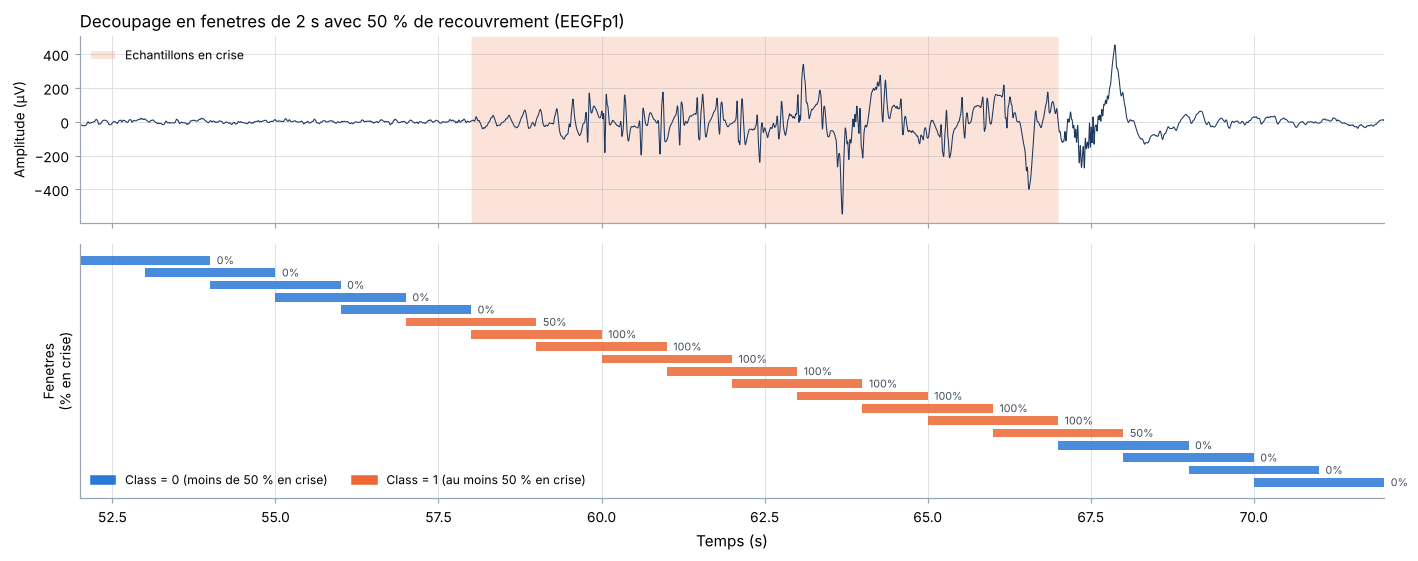

In [28]:
fig = viz.plot_windowing(clean, labeled["Class"].to_numpy(), windows.info, "EEGFp1", start=52, end=72)
save("q7_1_fenetres")

Chaque barre est une fenêtre de 2 s ; le pourcentage à droite est sa part d'échantillons
en crise. Les fenêtres à cheval sur le début ou la fin d'une crise basculent en classe 1 dès
que la moitié de leurs échantillons sont en crise.

Le nouveau dataset a bien la forme demandée : **une ligne = une fenêtre EEG**.

## Partie V : Extraction des caractéristiques

Pour une fenêtre `x` de N = 512 échantillons :

| Caractéristique | Formule | Ce qu'elle mesure |
| --- | --- | --- |
| Mean | (1/N) Σ xᵢ | niveau moyen |
| Std | √Variance | dispersion autour de la moyenne |
| Variance | (1/N) Σ (xᵢ − moyenne)² | dispersion (au carré) |
| Min, Max | min xᵢ, max xᵢ | valeurs extrêmes |
| Amplitude | Max − Min | amplitude crête à crête |
| RMS | √((1/N) Σ xᵢ²) | amplitude « efficace » |
| Energy | Σ xᵢ² | énergie de la fenêtre |

**Plusieurs canaux.** Chaque fenêtre contient 19 canaux EEG. On calcule chaque caractéristique
sur chaque canal, puis on garde la **médiane des 19 canaux**. Une absence est **généralisée**
(tous les canaux changent ensemble, voir Question 2), alors qu'un artefact ou une saturation
ne touche que quelques électrodes : la médiane garde la crise et ignore l'artefact.
Les canaux `SLI`, `ECG` et `EMG` ne sont pas utilisés.

Exemple sur `230102B_F`, au format demandé :

In [29]:
features_demo = window_features(windows.data, fs)
dataset_demo = pd.concat([windows.info[["window"]], features_demo[TEMPORAL_FEATURES],
                          windows.info[["Class"]]], axis=1)
display(dataset_demo.head().round(2))
display(dataset_demo[dataset_demo["Class"] == 1].head(3).round(2))

,window,Mean,Std,Variance,Min,Max,Amplitude,RMS,Energy,Class
0,1,-7.59,143.25,20519.80,-395.75,289.57,687.51,143.48,1.054001e+07,0
1,2,4.73,117.11,13715.57,-395.75,273.56,657.74,117.24,7.037893e+06,0
2,3,-9.87,61.41,3771.21,-133.31,177.54,308.31,62.19,1.980057e+06,0
3,4,37.24,252.05,63530.87,-626.56,874.44,1484.61,254.94,3.327752e+07,0
4,5,111.00,1221.17,1491254.76,-981.00,4668.14,5795.63,1225.89,7.694361e+08,0


,window,Mean,Std,Variance,Min,Max,Amplitude,RMS,Energy,Class
57,58,2.23,31.81,1011.87,-76.20,93.31,169.71,32.28,533515.10,1
58,59,3.44,89.45,8001.96,-227.09,316.72,579.41,89.83,4131630.32,1
59,60,-6.97,144.36,20839.56,-447.45,345.49,791.21,144.66,10713969.06,1


### Question 8 : dataset complet

On applique la même chaîne (filtrage, classe, fenêtres, caractéristiques) aux
19 enregistrements annotés. Le résultat est enregistré dans `data/processed/windows_features.csv`.

In [30]:
DATASET_FILE = ROOT / "data" / "processed" / "windows_features.csv"
dataset = build_dataset(annotations, ROOT, cache=DATASET_FILE, rebuild=True)

n0, n1 = (dataset["Class"] == 0).sum(), (dataset["Class"] == 1).sum()
print()
print(f"Nombre total de fenêtres : {len(dataset)}")
print(f"Fenêtres de classe 0     : {n0} ({n0 / len(dataset):.1%})")
print(f"Fenêtres de classe 1     : {n1} ({n1 / len(dataset):.1%})")
print(f"Colonnes : {list(dataset.columns)}")

190304A_E_0000 :  1574 fenetres,    8 en crise


191113A_D_0000 :  1809 fenetres,   20 en crise


210406A_F_0000 :  1453 fenetres,    9 en crise


210427B_C_0000 :  1245 fenetres,   19 en crise


210504B_C_0000 :  3120 fenetres,  146 en crise


...

230406B_A_0000 :  1224 fenetres,   48 en crise


230515B_G_0000 :  1206 fenetres,   48 en crise


230519A_E_0000 :  1215 fenetres,   37 en crise


230718A_A_0000 :  1205 fenetres,   74 en crise



Nombre total de fenêtres : 28994
Fenêtres de classe 0     : 27812 (95.9%)
Fenêtres de classe 1     : 1182 (4.1%)
Colonnes : ['recording_id', 'window', 'start_s', 'end_s', 'crisis_fraction', 'Mean', 'Std', 'Variance', 'Min', 'Max', 'Amplitude', 'RMS', 'Energy', 'Delta', 'Theta', 'Alpha', 'Beta', 'Class']


In [31]:
per_recording = dataset.groupby("recording_id").agg(
    fenetres=("Class", "size"), classe_1=("Class", "sum"))
per_recording["classe_0"] = per_recording["fenetres"] - per_recording["classe_1"]
per_recording["% crise"] = (per_recording["classe_1"] / per_recording["fenetres"] * 100).round(1)
display(per_recording[["fenetres", "classe_0", "classe_1", "% crise"]].T)

recording_id,190304A_E_0000,191113A_D_0000,210406A_F_0000,210427B_C_0000,210504B_C_0000,210914B_A_0000,210928B_B_0000,211027B_C_0000,211104B_D_0000,220106A_A_0000,220121B_D_0000,230102B_F_0000,230105B_H_0000,230210B_D_0000,230224B_B_0000,230406B_A_0000,230515B_G_0000,230519A_E_0000,230718A_A_0000
fenetres,1574.0,1809.0,1453.0,1245.0,3120.0,1204.0,1343.0,1254.0,1209.0,1220.0,1291.0,1224.0,3599.0,1172.0,1427.0,1224.0,1206.0,1215.0,1205.0
classe_0,1566.0,1789.0,1444.0,1226.0,2974.0,1017.0,1286.0,1123.0,1164.0,1181.0,1238.0,1080.0,3554.0,1149.0,1378.0,1176.0,1158.0,1178.0,1131.0
classe_1,8.0,20.0,9.0,19.0,146.0,187.0,57.0,131.0,45.0,39.0,53.0,144.0,45.0,23.0,49.0,48.0,48.0,37.0,74.0
% crise,0.5,1.1,0.6,1.5,4.7,15.5,4.2,10.4,3.7,3.2,4.1,11.8,1.3,2.0,3.4,3.9,4.0,3.0,6.1


Vérifications :

* chaque enregistrement de D secondes donne D − 1 fenêtres (par exemple 1 225 s → 1 224 fenêtres) ;
* 28 994 fenêtres au total, dont **1 182 en crise (4,1 %)** : le déséquilibre de la Question 6
  se retrouve au niveau des fenêtres ;
* l'apport en crise varie beaucoup d'un patient à l'autre (de 0,5 % à 15,5 % des fenêtres).

**Contrôle de l'alignement des annotations.** Pour chaque crise, on compare le RMS médian des
fenêtres de crise au RMS médian hors crise du même enregistrement. Si les annotations étaient
décalées, ce rapport serait proche de 1.

In [32]:
rows = []
for _, crise in annotations.iterrows():
    rec = dataset[dataset["recording_id"] == file_id(crise["recording_id"])]
    baseline = rec.loc[rec["Class"] == 0, "RMS"].median()
    inside = rec[(rec["start_s"] >= crise["start_s"] - 1) & (rec["end_s"] <= crise["end_s"] + 1)]
    rows.append({"enregistrement": crise["recording_id"], "crise": crise["seizure"],
                 "rapport RMS crise / hors crise": inside["RMS"].median() / baseline})
alignment = pd.DataFrame(rows)

summary = alignment.groupby("enregistrement")["rapport RMS crise / hors crise"].agg(["min", "median", "max"])
display(summary.round(1).T)
print("Crises avec un rapport < 1,5 :")
display(alignment[alignment["rapport RMS crise / hors crise"] < 1.5].round(2))

enregistrement,190304A-E,191113A-D,210406A-F,210427B-C,210504B-C,210914B-A,210928B-B,211027B-C,211104B-D,220106A-A,220121B-D,230102B-F,230105B-H,230210B-D,230224B-B,230406B-A,230515B-G,230519A-E,230718A-A
min,3.3,4.8,8.0,7.7,0.8,2.8,10.4,4.1,8.6,4.8,5.0,3.8,6.3,6.3,3.7,8.5,4.7,5.3,1.8
median,3.3,5.2,8.0,7.7,6.0,4.1,10.5,5.4,9.3,4.9,5.1,6.2,7.0,6.3,3.8,8.9,7.7,5.5,1.8
max,3.3,5.5,8.0,7.7,6.5,4.8,10.6,6.1,9.6,5.0,5.5,7.5,8.2,6.3,4.2,9.6,10.6,5.7,1.9


Crises avec un rapport < 1,5 :


,enregistrement,crise,rapport RMS crise / hors crise
16,210504B-C,12,0.81


Pendant les crises, l'amplitude est en général **3 à 10 fois** plus forte que hors crise :
les annotations sont bien alignées sur le signal. Deux cas à retenir :

* `210504B-C`, crise 12 (2 399 s, annotée 60 s) : la décharge ne dure qu'environ 20 s,
  le reste de l'intervalle est calme. L'annotation est la même dans l'ancien fichier, on la garde
  telle quelle, mais une partie de ces fenêtres « crise » ressemble à du hors crise.
* `230718A-A` : le rapport n'est que de 1,8 pour toutes les crises, car le niveau de base de
  ce patient est 4 fois plus élevé que celui des autres (RMS médian hors crise de 93 µV contre
  20 µV environ). Les seuils d'amplitude appris sur les autres patients ne s'appliquent pas
  directement à lui (piste d'amélioration : normaliser par enregistrement).

## Partie VI : Analyse fréquentielle

Pour chaque fenêtre et chaque canal, on calcule la **transformée de Fourier rapide** (FFT) :

1. on retire la moyenne, puis on multiplie par une fenêtre de Hann (limite les fuites spectrales
   dues aux bords de la fenêtre) ;
2. `numpy.fft.rfft` donne le spectre, avec une résolution de 1 / 2 s = **0,5 Hz** ;
3. la densité spectrale de puissance (DSP) est |X(f)|² normalisée, en µV²/Hz ;
4. la puissance d'une bande est l'**intégrale de la DSP** sur cette bande (en µV²), puis on prend
   la médiane des 19 canaux, comme pour les caractéristiques temporelles.

Exemple sur une fenêtre hors crise et une fenêtre de crise du même enregistrement :

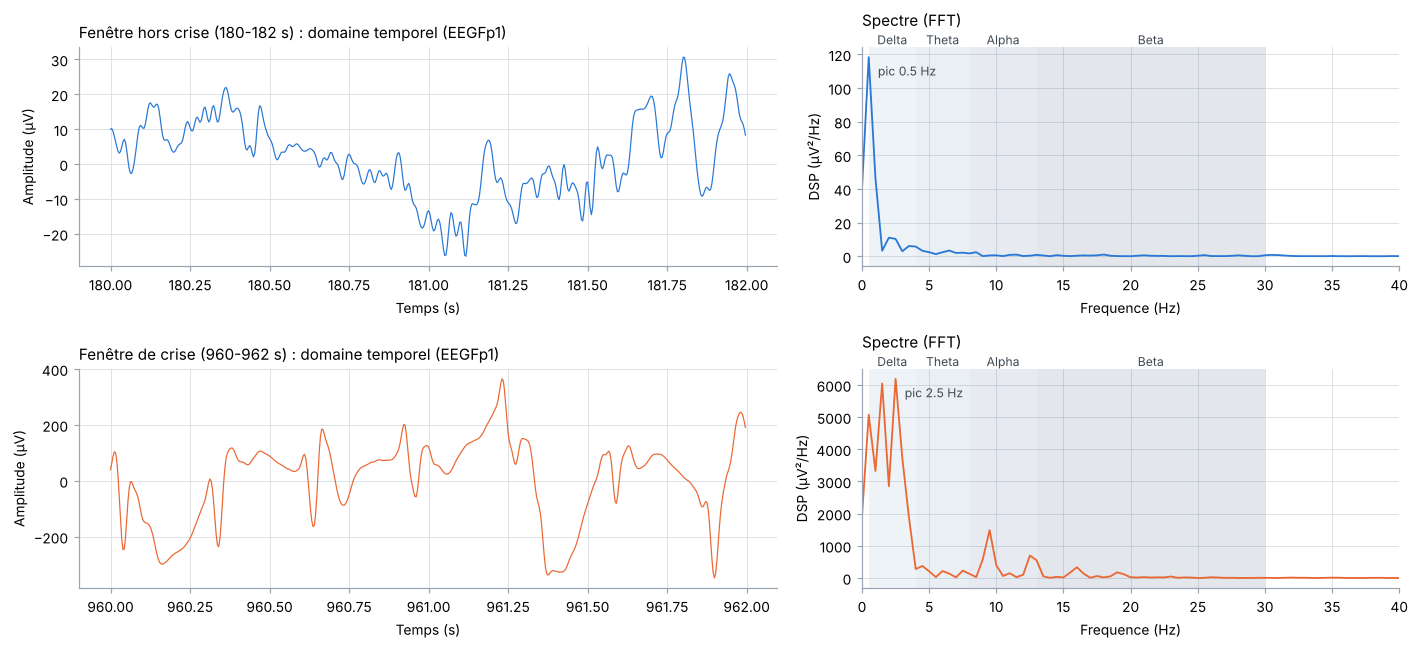

In [33]:
info = windows.info
idx_normal = int(info.index[(info["start_s"] == 180)][0])     # hors crise
idx_crisis = int(info.index[(info["start_s"] == 960)][0])     # crise 7 (956-980 s)

fig = viz.plot_window_fft(windows.data, info,
                          {"Fenêtre hors crise (180-182 s)": idx_normal,
                           "Fenêtre de crise (960-962 s)": idx_crisis},
                          channel_index=EEG_CHANNELS.index("EEGFp1"), channel_name="EEGFp1",
                          sampling_rate=fs, bands=BANDS)
save("q8_1_fft_fenetres")

* **Hors crise** : signal irrégulier de faible amplitude (±30 µV). La puissance est faible et
  surtout sous 2 Hz (pic à 0,5 Hz : une dérive lente), sans rythme net.
* **Crise** : amplitude 10 fois plus grande et motif répété (pointe brève puis onde lente).
  La puissance est **50 fois plus forte** (6 000 µV²/Hz contre 120) et se concentre entre
  **1,5 et 3 Hz** : c'est le rythme pointe-onde de l'absence (environ 3 Hz au début de la crise,
  un peu plus lent ensuite ; cette fenêtre est 4 s après le début). Les petits pics vers 9,5 et
  12,5 Hz viennent des **pointes**, qui sont des variations rapides. C'est pour cela que toutes
  les bandes augmentent en crise, Delta en premier.

### Question 9 : puissance par bande

Bandes utilisées : Delta 0,5–4 Hz, Theta 4–8 Hz, Alpha 8–13 Hz, Beta 13–30 Hz.
Les quatre colonnes sont déjà dans le dataset :

,recording_id,window,start_s,Delta,Theta,Alpha,Beta,Class
0,190304A_E_0000,1,0.0,37.37,17.68,14.52,13.19,0
1,190304A_E_0000,2,1.0,55.20,58.56,155.39,84.57,0
2,190304A_E_0000,3,2.0,91.28,41.60,106.21,49.76,0
30,190304A_E_0000,31,30.0,39.55,53.46,101.21,38.44,0
31,190304A_E_0000,32,31.0,53.53,57.66,110.25,31.88,0


Dimensions finales du dataset : (28994, 18) -> 12 caractéristiques + Class


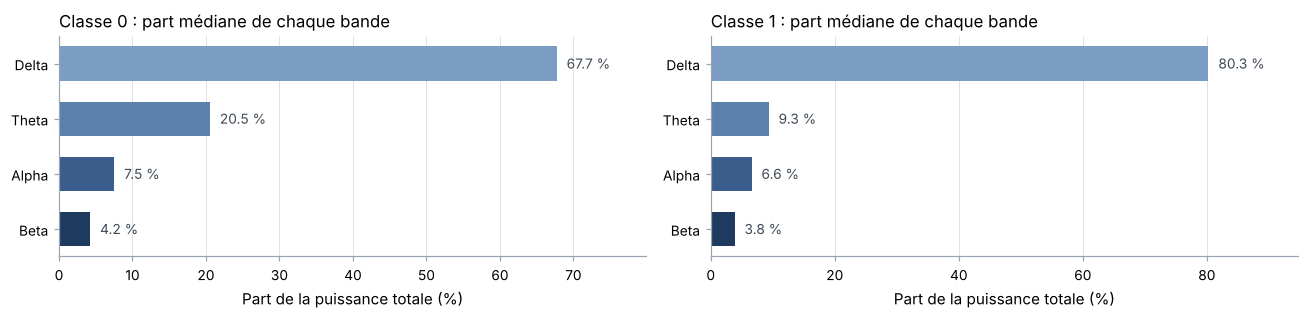

In [34]:
display(dataset[["recording_id", "window", "start_s", "Delta", "Theta", "Alpha", "Beta", "Class"]]
        .iloc[[0, 1, 2, 30, 31]].round(2))
print("Dimensions finales du dataset :", dataset.shape, "->", len(FEATURES), "caractéristiques + Class")

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, value in zip(axes, (0, 1)):
    powers = dataset.loc[dataset["Class"] == value, list(BANDS)].median()
    viz.plot_band_powers(powers, ax=ax, title=f"Classe {value} : part médiane de chaque bande")
save("q9_1_bandes_par_classe")

En crise, toutes les bandes augmentent en valeur absolue (médianes multipliées par 19 à 50,
voir Question 10), mais **Delta augmente le plus** : sa part passe de 68 % à 80 % de la
puissance, car l'énergie de la crise se concentre dans le rythme lent pointe-onde.

## Partie VII : Analyse exploratoire

### Question 10 : comparaison des deux classes

In [35]:
comparison = class_comparison(dataset, FEATURES)
display(comparison[["moyenne classe 0", "moyenne classe 1", "mediane classe 0",
                    "mediane classe 1", "rapport des medianes (1/0)"]].round(2))

,moyenne classe 0,moyenne classe 1,mediane classe 0,mediane classe 1,rapport des medianes (1/0)
caracteristique,,,,,
Amplitude,169.23,620.71,105.49,619.60,5.87
Max,84.73,289.37,50.65,281.89,5.57
Min,-83.46,-328.40,-51.97,-320.23,NaN
Theta,408.31,2279.58,66.18,1276.17,19.28
Std,34.75,136.75,20.77,132.24,6.37
Variance,6949.25,25710.84,431.42,17487.34,40.53
Beta,68.62,1061.38,13.64,524.91,38.48
Energy,3593825.59,13206329.80,223139.66,8972505.67,40.21
RMS,34.93,136.99,20.88,132.38,6.34


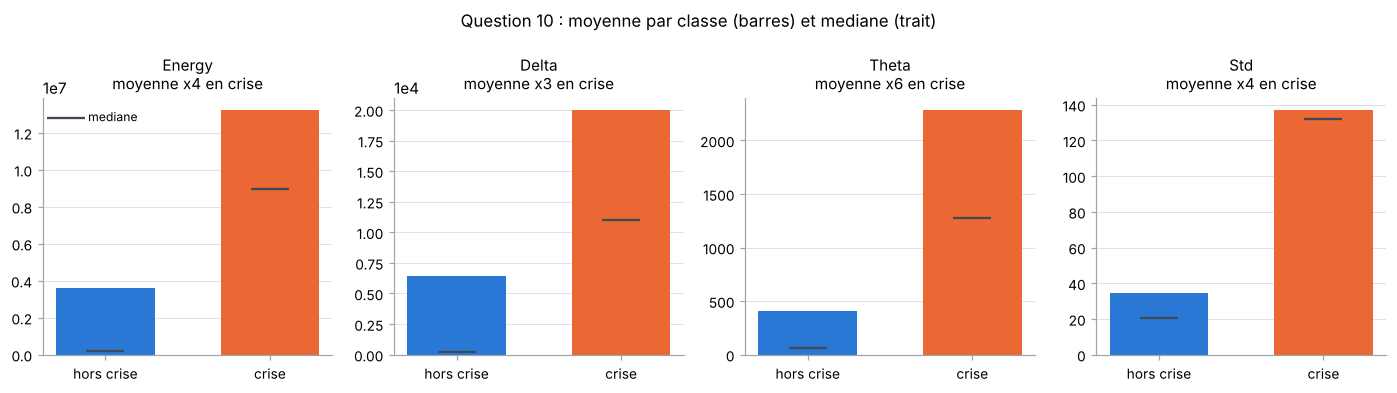

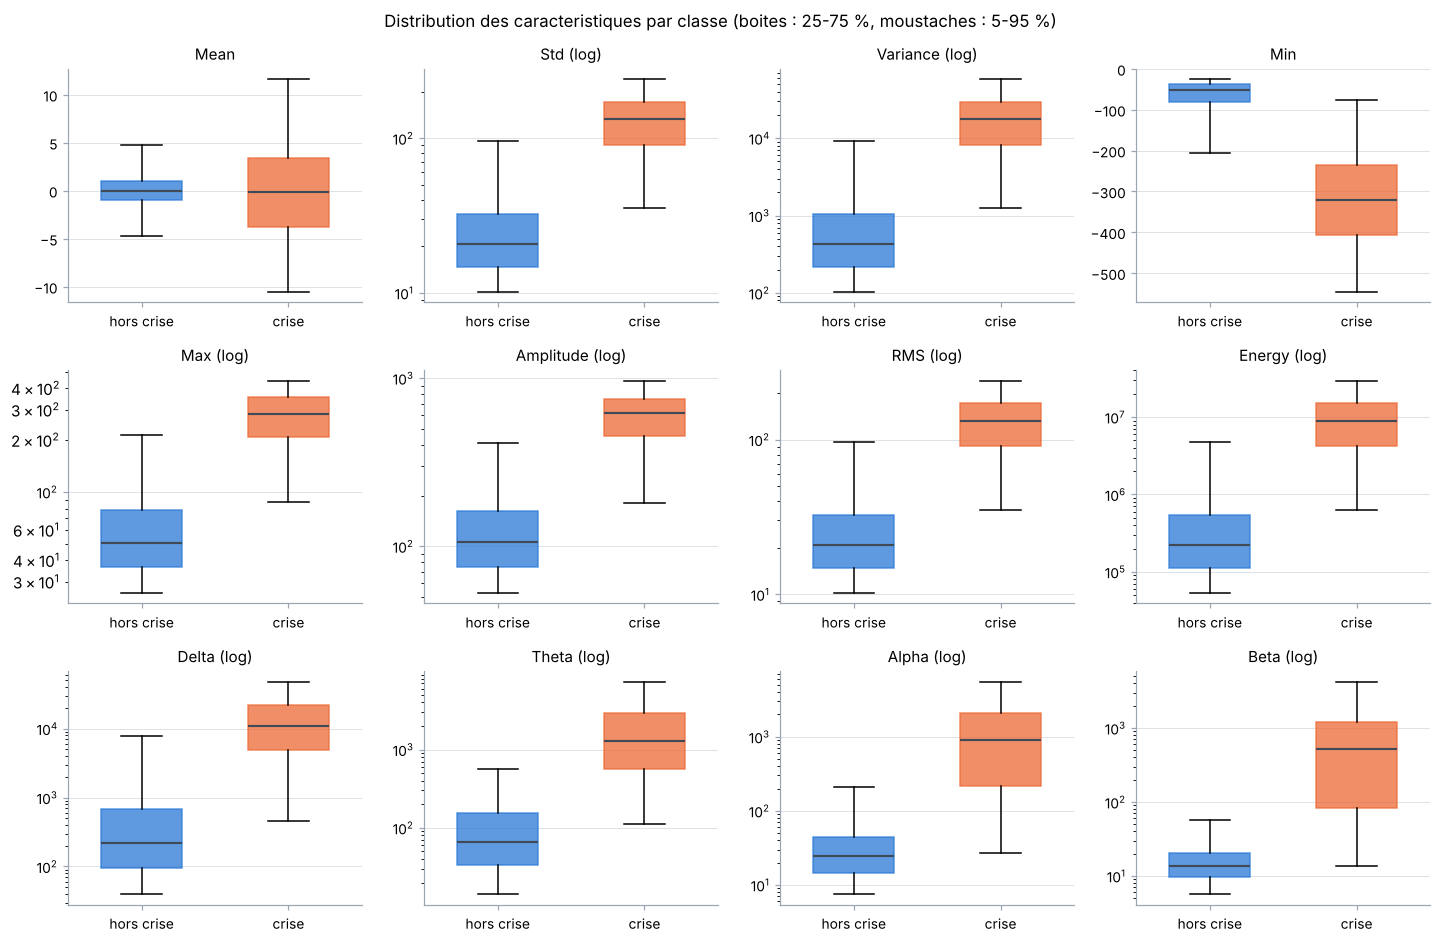

In [36]:
fig = plot_class_means(dataset, features=("Energy", "Delta", "Theta", "Std"))
save("q10_1_moyennes_par_classe")

fig = plot_class_boxplots(dataset, FEATURES)
save("q10_2_distributions_par_classe")

**Observations**

* **Énergie** : la médiane est **40 fois** plus grande en crise. La moyenne, elle, n'est que
  4 fois plus grande, car quelques artefacts hors crise ont une énergie énorme et tirent la
  moyenne de la classe 0 vers le haut. La médiane décrit mieux une fenêtre « typique ».
* **Delta** : médiane ×50 en crise, mais beaucoup de recouvrement entre les boîtes. Les artefacts
  lents (mouvements des yeux, hyperpnée) donnent aussi du Delta hors crise.
* **Theta** : médiane ×19 en crise, et les boîtes se recouvrent très peu : c'est une variable
  qui sépare bien les classes.
* **Écart-type** : ×6 en crise (21 µV contre 132 µV), ce qui confirme l'observation visuelle
  de la Question 2 (amplitude multipliée par 3 à 5, plus sur certains patients).
* **Mean** : la seule variable qui ne change pas (proche de 0 µV dans les deux classes). C'est
  normal : le filtre passe-bande 0,5–40 Hz retire la composante continue.
* Les boîtes se recouvrent peu pour toutes les variables sauf Mean : chaque variable seule sépare
  déjà assez bien les classes, mais pas parfaitement.
* Remarque : 64 fenêtres hors crise sont presque plates (Std < 1 µV). Elles viennent de trois
  enregistrements (`191113A_D`, `230224B_B`, `230406B_A`) où le signal est coupé environ 20 s.
  Elles sont gardées : ce sont bien des fenêtres sans crise.

### Question 11 : matrice de corrélation

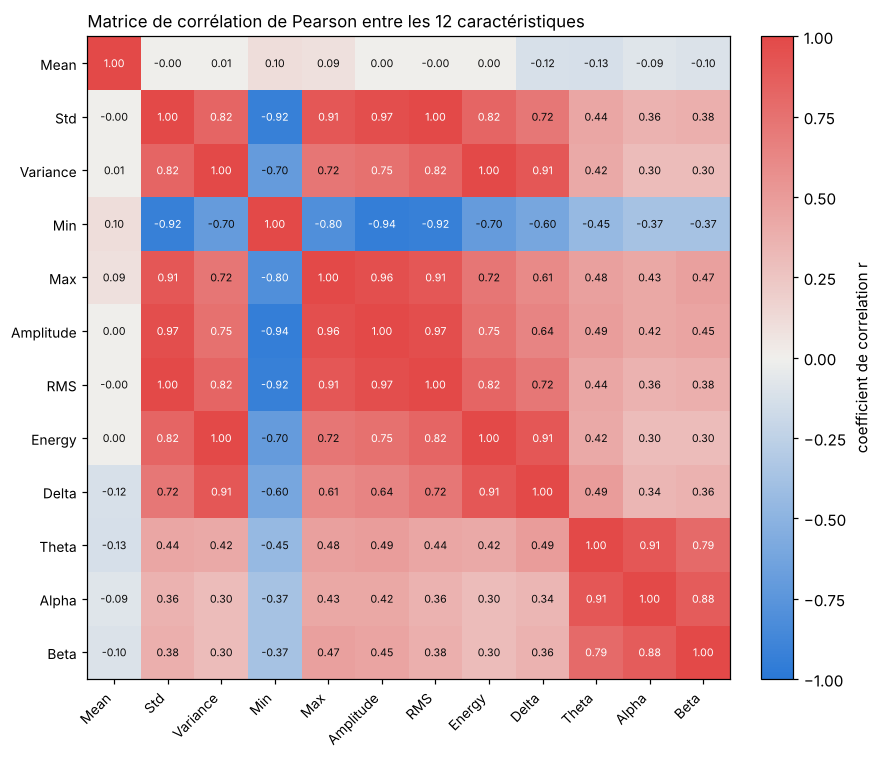

Couples fortement corrélés (|r| ≥ 0,9, Pearson) :


,caracteristique 1,caracteristique 2,r
0,Variance,Energy,1.000
1,Std,RMS,1.000
2,Amplitude,RMS,0.967
3,Std,Amplitude,0.967
4,Max,Amplitude,0.956
5,Min,Amplitude,-0.940
6,Min,RMS,-0.924
7,Std,Min,-0.924
8,Max,RMS,0.913
9,Std,Max,0.913


In [37]:
corr = dataset[FEATURES].corr()          # Pearson
fig = plot_correlation(corr, "Matrice de corrélation de Pearson entre les 12 caractéristiques")
save("q11_1_correlation")

print("Couples fortement corrélés (|r| ≥ 0,9, Pearson) :")
display(correlated_pairs(corr, 0.9).round(3))

In [38]:
# Pearson ne mesure que les liens linéaires. Variance = Std² est un lien parfait mais non linéaire :
# la corrélation de rang (Spearman) le voit, Pearson non.
spearman = dataset[FEATURES].corr(method="spearman")
print(f"Std / Variance : Pearson r = {corr.loc['Std', 'Variance']:.2f}, Spearman ρ = {spearman.loc['Std', 'Variance']:.2f}")
print(f"RMS / Energy   : Pearson r = {corr.loc['RMS', 'Energy']:.2f}, Spearman ρ = {spearman.loc['RMS', 'Energy']:.2f}")

display(comparison[["AUC (pouvoir discriminant)"]].round(3).T)

Std / Variance : Pearson r = 0.82, Spearman ρ = 1.00
RMS / Energy   : Pearson r = 0.82, Spearman ρ = 1.00


caracteristique,Amplitude,Max,Min,Theta,Std,Variance,Beta,Energy,RMS,Alpha,Delta,Mean
AUC (pouvoir discriminant),0.939,0.937,0.934,0.933,0.932,0.932,0.932,0.932,0.932,0.93,0.918,0.508


**1. Quelles caractéristiques sont fortement corrélées ?**

Deux groupes se dégagent :

* **le groupe « amplitude »** : Std, RMS, Amplitude, Max et Min (|r| entre 0,91 et 1). Min est
  corrélé *négativement* : quand l'amplitude augmente, le minimum devient plus négatif.
  Variance, Energy et Delta forment un sous-groupe (r ≈ 0,91 à 1).
* **le groupe des bandes rapides** : Theta, Alpha et Beta (r de 0,79 à 0,91).

**2. Certaines caractéristiques sont-elles redondantes ? Oui.**

* **Std et RMS** (r = 1,00) : RMS² = Variance + Mean², et Mean ≈ 0 après filtrage, donc RMS ≈ Std.
* **Variance et Energy** (r = 1,00) : Energy = N × RMS² ≈ 512 × Variance.
* **Variance et Std** sont la même information (Variance = Std²). Pearson ne donne que r = 0,82 car
  la relation n'est pas linéaire, mais la corrélation de rang de Spearman vaut 1,00.
* **Amplitude = Max − Min** est presque entièrement expliquée par Std (r = 0,97).

Au final, sur les 8 caractéristiques temporelles, il y a surtout **une** information
(« quelle est l'amplitude de la fenêtre ? »), mesurée de plusieurs façons. On pourrait garder
seulement Std (ou RMS) et Amplitude sans perdre grand-chose.

**3. Quelles caractéristiques sont les plus discriminantes ?**

On utilise l'**AUC univariée** : la probabilité qu'une fenêtre de crise prise au hasard ait
une valeur plus grande qu'une fenêtre hors crise (0,5 = aucune séparation, 1 = séparation parfaite).

* les meilleures sont **Amplitude (0,94), Max, Min, Theta, Std/RMS (0,93)** ; les écarts entre
  elles sont très faibles, ce qui est logique puisqu'elles mesurent presque la même chose ;
* les bandes Beta, Alpha et Delta suivent (0,92 à 0,93) ; Delta est la moins bonne des
  quatre, à cause des artefacts lents hors crise ;
* **Mean (0,51) n'apporte aucune information**.

Aucune variable seule ne dépasse 0,94 : combiner les variables d'amplitude et de fréquence
devrait améliorer la séparation. C'est le rôle des modèles de la Partie VIII.

## Partie VIII : Construction du modèle de Data Mining

### Séparation 80 % / 20 % stratifiée

Les 12 caractéristiques forment `X`, la colonne `Class` forme `y`. La séparation est
**stratifiée** (`stratify=y`) : la proportion de fenêtres de crise est la même dans les deux jeux.
`random_state=42` rend le résultat reproductible.

In [39]:
from src.training import split_data, tune_models, tuning_summary, depth_curve, LogTransformer, RANDOM_STATE
from src.evaluation import (results_table, confusion_table, plot_confusion_matrices, plot_metric_comparison,
                            compare_trees, group_evaluation, plot_depth_curve, plot_feature_importances)

X_train, X_test, y_train, y_test = split_data(dataset, FEATURES, test_size=0.2)

split_table = pd.DataFrame({
    "fenêtres": [len(y_train), len(y_test)],
    "classe 0": [(y_train == 0).sum(), (y_test == 0).sum()],
    "classe 1": [(y_train == 1).sum(), (y_test == 1).sum()],
    "% crise": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}, index=["entraînement (80 %)", "test (20 %)"])
display(split_table)

,fenêtres,classe 0,classe 1,% crise
entraînement (80 %),23195,22249,946,4.08
test (20 %),5799,5563,236,4.07


La proportion de crises est bien identique (4,08 % et 4,07 %).

### Question 12 : construction des modèles

**Protocole, identique pour tous les modèles**

1. Le jeu de test est mis de côté et n'est utilisé qu'une fois, à la Partie IX.
2. Sur l'entraînement, chaque modèle teste une grille d'hyperparamètres par **validation croisée
   stratifiée à 5 plis** (`GridSearchCV`). Le critère de choix est le **F1-score de la classe crise**,
   pas l'accuracy (Question 6).
3. La grille contient aussi `class_weight` : `None` (rien) ou `balanced` (une erreur sur une crise
   coûte 24 fois plus cher qu'une erreur hors crise). La validation croisée décide si cette
   pondération aide.
4. Le meilleur réglage est ré-entraîné sur tout l'entraînement.

| Modèle | Préparation des données | Hyperparamètres explorés |
| --- | --- | --- |
| 1. Decision Tree (Gini **et** Entropie) | aucune (un arbre ne regarde que l'ordre des valeurs) | `max_depth`, `min_samples_leaf`, `class_weight` |
| 2. Random Forest (200 arbres) | aucune | `min_samples_leaf`, `class_weight` |
| 3. KNN | log10 des variables positives, puis standardisation | `n_neighbors`, `weights` |
| 4. SVM, noyau RBF | log10, puis standardisation | `C`, `gamma`, `class_weight` |
| 5. **Gradient Boosting** (modèle proposé en plus) | aucune | `learning_rate`, `max_leaf_nodes`, `min_samples_leaf`, `class_weight` |
| Référence | aucune | répond toujours 0 |

**Pourquoi le log puis la standardisation pour KNN et SVM ?** Ces modèles calculent des
distances. Sans mise à l'échelle, Energy (de l'ordre de 10⁶) écraserait Mean (de l'ordre de 1).
Et l'énergie s'étale sur plusieurs ordres de grandeur : même standardisée, quelques fenêtres
d'artefact très énergiques restent très loin de tout le reste. Le log10 ramène ces variables
sur une échelle régulière. La cellule de contrôle plus bas montre le gain.

La cellule suivante lance toutes les recherches (environ 6 minutes).

In [40]:
tuned = tune_models(X_train, y_train)
display(tuning_summary(tuned))

Decision Tree (Gini)       F1 (CV) = 0.725   recherche : 100.3 s


Decision Tree (Entropie)   F1 (CV) = 0.705   recherche : 110.8 s


Random Forest              F1 (CV) = 0.744   recherche : 252.8 s


KNN                        F1 (CV) = 0.737   recherche :  63.6 s


SVM (RBF)                  F1 (CV) = 0.742   recherche : 459.1 s


Gradient Boosting          F1 (CV) = 0.732   recherche : 160.2 s


,modele,combinaisons testees,hyperparametres retenus,F1 (CV 5 plis),temps d'entrainement (s)
0,Decision Tree (Gini),72,"class_weight=None, max_depth=6, min_samples_le...",0.725 ± 0.033,0.25
1,Decision Tree (Entropie),72,"class_weight=None, max_depth=8, min_samples_le...",0.705 ± 0.032,0.38
2,Random Forest,4,"class_weight=None, min_samples_leaf=1",0.744 ± 0.028,14.94
3,KNN,18,"n_neighbors=11, weights=distance",0.737 ± 0.040,0.06
4,SVM (RBF),18,"C=10, class_weight=None, gamma=0.3",0.742 ± 0.032,5.46
5,Gradient Boosting,16,"class_weight=None, learning_rate=0.05, max_lea...",0.732 ± 0.029,34.88
6,Reference : toujours 0,1,strategy=most_frequent,0.000 ± 0.000,0.00


#### Modèle 1 : arbre de décision, indice de Gini contre entropie

À chaque nœud, l'arbre choisit la question (« Theta > 300 ? ») qui rend les deux groupes
obtenus les plus **purs** possible. Deux mesures d'impureté sont possibles, avec `p` la part de
fenêtres de crise dans le nœud :

| Critère | Formule (2 classes) | Nœud pur (p = 0 ou 1) | Nœud mélangé (p = 0,5) |
| --- | --- | --- | --- |
| **Gini** | 1 − p² − (1 − p)² | 0 | 0,5 |
| **Entropie** | − p log₂ p − (1 − p) log₂(1 − p) | 0 | 1 |

L'indice de Gini est la probabilité de se tromper en tirant une étiquette au hasard selon les
proportions du nœud. L'entropie mesure l'incertitude au sens de la théorie de l'information ; la
baisse d'entropie après une division est le **gain d'information**. Les deux courbes ont presque la
même forme : on s'attend donc à des arbres proches.

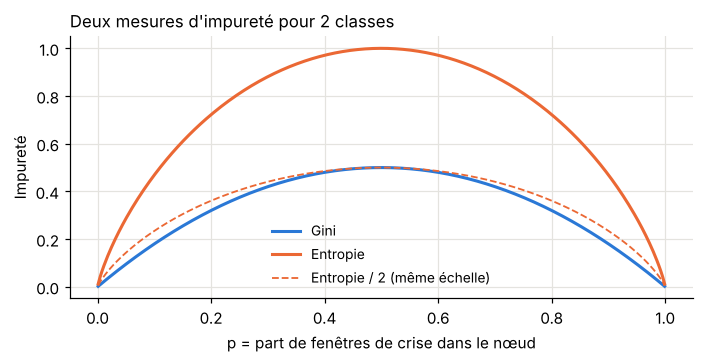

In [41]:
p = np.linspace(0.001, 0.999, 300)
gini = 1 - p**2 - (1 - p)**2
entropy = -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(p, gini, color="#2a78d6", linewidth=2, label="Gini")
ax.plot(p, entropy, color="#eb6834", linewidth=2, label="Entropie")
ax.plot(p, entropy / 2, color="#eb6834", linewidth=1.2, linestyle="--", label="Entropie / 2 (même échelle)")
ax.set_xlabel("p = part de fenêtres de crise dans le nœud")
ax.set_ylabel("Impureté")
ax.set_title("Deux mesures d'impureté pour 2 classes", fontsize=11, loc="left")
ax.legend(frameon=False, fontsize=9)
ax.grid(True, color="#e4e3df"); ax.spines[["top", "right"]].set_visible(False)
save("q12_1_gini_entropie_formules")

**Comparaison selon la profondeur.** Pour comparer les deux critères à complexité égale,
on fait varier la profondeur maximale (les autres réglages restent par défaut) et on mesure le F1
en entraînement et en validation croisée.

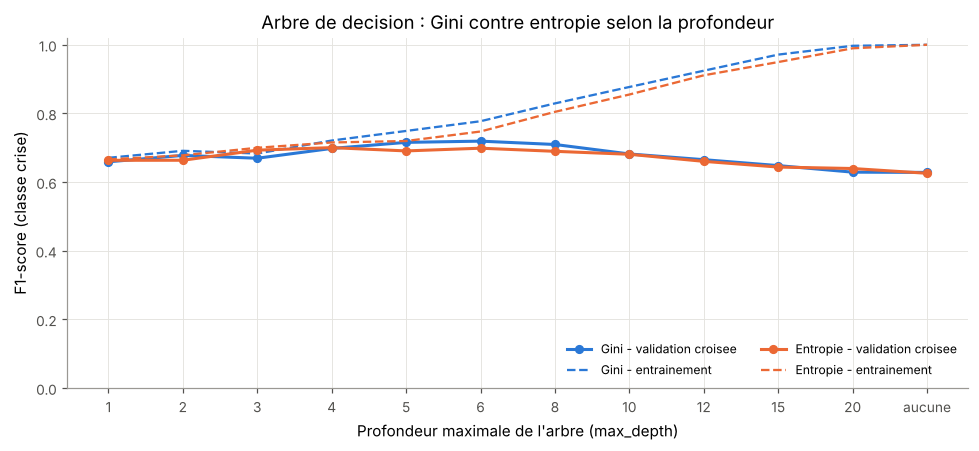

max_depth,1,2,3,4,5,6,8,10,12,15,20,aucune
criterion,,,,,,,,,,,,
entropy,0.664,0.664,0.693,0.700,0.691,0.699,0.69,0.681,0.660,0.644,0.640,0.626
gini,0.659,0.678,0.670,0.698,0.716,0.719,0.71,0.682,0.665,0.648,0.629,0.628


In [42]:
curve = depth_curve(X_train, y_train)
fig = plot_depth_curve(curve)
save("q12_2_arbre_profondeur")

display(curve.pivot(index="max_depth", columns="criterion", values="F1 validation").T.round(3))

* Les deux courbes de validation restent proches : à profondeur égale, Gini et entropie donnent
  presque la même qualité (écarts de 0,01 à 0,03, du même ordre que la variation d'un pli à
  l'autre, environ 0,03). Gini est un peu devant entre 5 et 8 niveaux (0,72 contre 0,69–0,70).
* Au-delà de 8 niveaux, le F1 d'entraînement continue de monter vers 1 alors que celui de
  validation baisse : l'arbre **apprend par cœur** (surapprentissage). Sans limite de profondeur,
  il atteint F1 = 1 en entraînement et seulement 0,63 en validation.
* Le meilleur compromis est autour de 4 à 6 niveaux.

**Comparaison des deux arbres optimisés (recherche sur grille complète) :**

In [43]:
trees = ["Decision Tree (Gini)", "Decision Tree (Entropie)"]
display(compare_trees(tuned, trees, X_test, y_test))

,Decision Tree (Gini),Decision Tree (Entropie)
Accuracy,0.979,0.98
Precision,0.782,0.808
Recall,0.682,0.678
F1-score,0.729,0.737
F1 validation croisee,0.725,0.705
profondeur,6,8
nombre de feuilles,41,82
temps d'entrainement (ms),247.2,382.7
hyperparametres,"class_weight=None, max_depth=6, min_samples_le...","class_weight=None, max_depth=8, min_samples_le..."
predictions identiques (%),99.28,99.28


**Conclusion Gini contre entropie**

* Les performances sont **équivalentes** : F1 de 0,73 et 0,74 sur le test, de 0,725 et 0,705 en
  validation croisée. Les écarts (environ 0,01 à 0,02) sont plus petits que l'écart-type entre plis
  (0,03) : ils ne sont pas significatifs.
* Les deux arbres prennent la **même décision pour 99,3 % des fenêtres de test**.
* L'arbre **Gini est plus simple** (profondeur 6, 41 feuilles contre profondeur 8, 82 feuilles) et
  un peu plus rapide à entraîner : Gini n'a pas de logarithme à calculer.
* On retient donc **Gini** : même qualité, modèle deux fois plus petit et plus facile à lire.

Les trois premiers niveaux de l'arbre Gini :

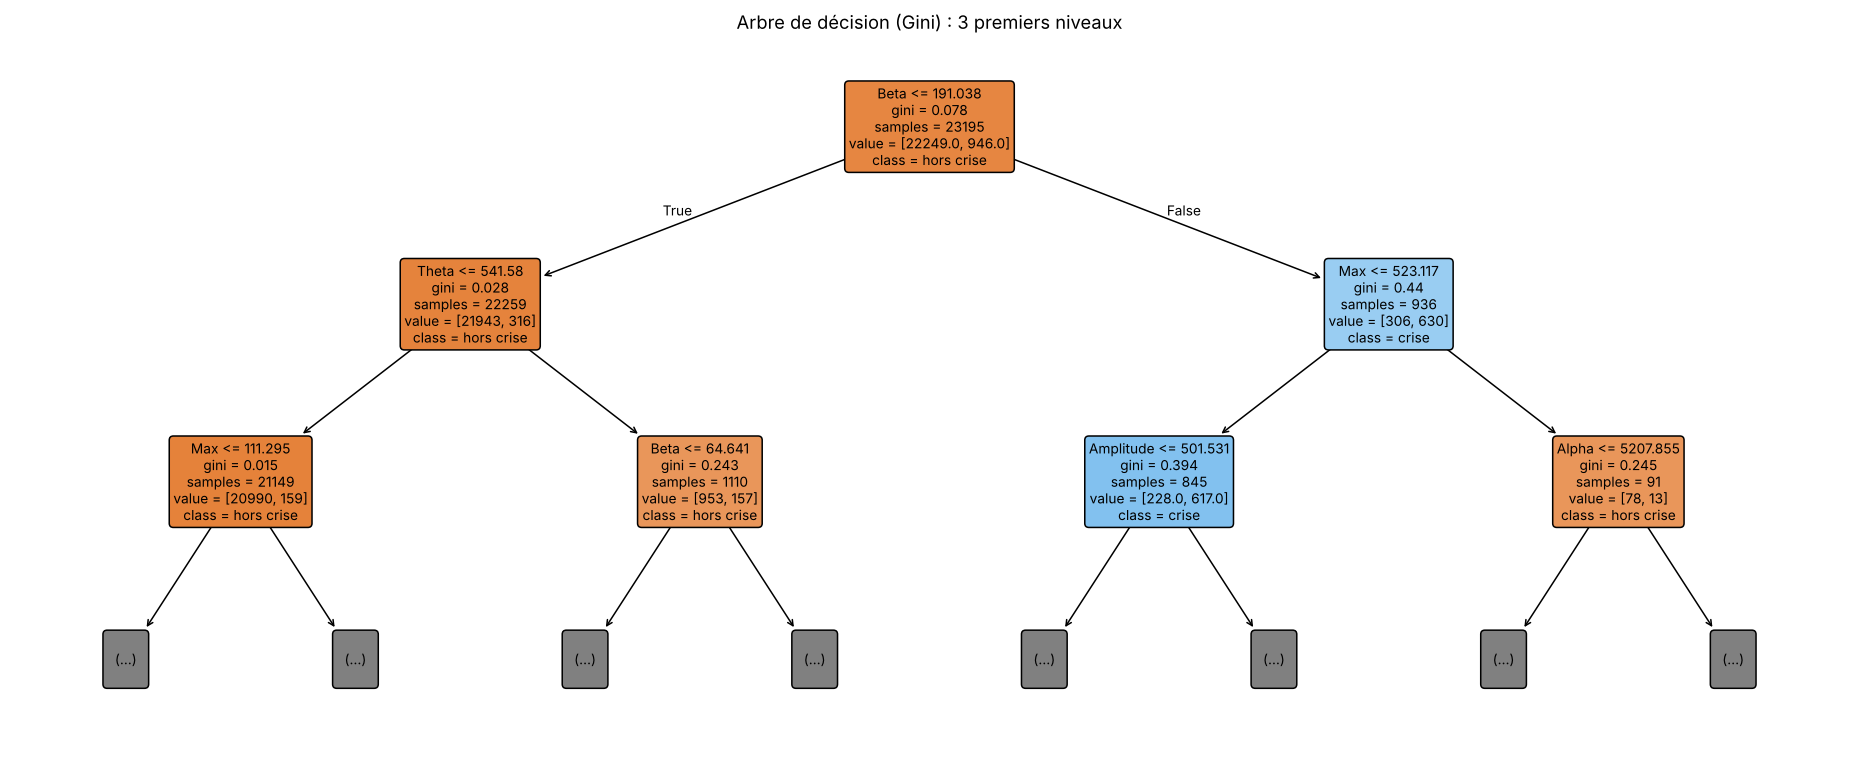

In [44]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(17, 7))
plot_tree(tuned["Decision Tree (Gini)"].estimator, max_depth=2, feature_names=FEATURES,
          class_names=["hors crise", "crise"], filled=True, rounded=True, impurity=True,
          proportion=False, fontsize=9, ax=ax)
ax.set_title("Arbre de décision (Gini) : 3 premiers niveaux", fontsize=12)
save("q12_3_arbre_gini")

Lecture : chaque case donne la question posée, l'indice de Gini du nœud, le nombre de fenêtres
(`samples`), leur répartition (`value` = [hors crise, crise]) et la classe majoritaire.

* La racine contient 4,1 % de crises : Gini = 1 − 0,959² − 0,041² = **0,078**.
* La première question est **Beta ≤ 191 µV²**. Elle isole 936 fenêtres dont 67 % sont des crises
  (Gini = 0,44) : les pointes de la pointe-onde sont des variations rapides, qui donnent de la
  puissance en Beta, alors que les artefacts lents (yeux, mouvements) n'en donnent pas.
* L'arbre affine ensuite avec Theta, Max, Amplitude et Alpha.

#### Modèle 2 : Random Forest

Une forêt aléatoire entraîne 200 arbres profonds, chacun sur un tirage avec remise des fenêtres
et en ne regardant qu'une partie des variables à chaque nœud. Elle vote à la majorité.
Chaque arbre surapprend, mais leurs erreurs sont différentes et se compensent dans le vote.

#### Modèle 3 : KNN

Une fenêtre reçoit la classe majoritaire de ses k plus proches voisines dans l'espace des 12
caractéristiques (après log et standardisation).

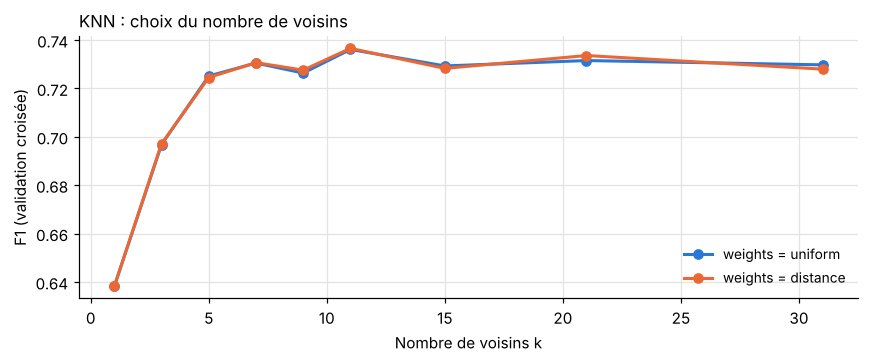

In [45]:
knn_cv = pd.DataFrame(tuned["KNN"].search.cv_results_)
knn_cv["k"] = knn_cv["param_model__n_neighbors"]

fig, ax = plt.subplots(figsize=(8, 3.4))
for color, weight in zip(["#2a78d6", "#eb6834"], ["uniform", "distance"]):
    part = knn_cv[knn_cv["param_model__weights"] == weight].sort_values("k")
    ax.plot(part["k"], part["mean_test_score"], marker="o", color=color, linewidth=2, label=f"weights = {weight}")
ax.set_xlabel("Nombre de voisins k")
ax.set_ylabel("F1 (validation croisée)")
ax.set_title("KNN : choix du nombre de voisins", fontsize=11, loc="left")
ax.legend(frameon=False, fontsize=9)
ax.grid(True, color="#e4e3df"); ax.spines[["top", "right"]].set_visible(False)
save("q12_4_knn_k")

Avec k = 1, le modèle copie le bruit de l'entraînement ; quand k devient grand, les voisins
viennent surtout de la classe majoritaire et les crises sont noyées. Le meilleur compromis est
autour de **k = 11** avec un vote pondéré par la distance.

#### Modèle 4 : SVM à noyau RBF

Le SVM cherche la frontière qui sépare les classes avec la plus grande marge. Le noyau RBF
permet une frontière courbe. `C` règle la tolérance aux erreurs d'entraînement, `gamma` la portée
de chaque point (grand `gamma` = frontière plus sinueuse).

In [46]:
svm_cv = pd.DataFrame(tuned["SVM (RBF)"].search.cv_results_)
svm_cv["C"] = svm_cv["params"].apply(lambda p: p["model__C"])
svm_cv["gamma"] = svm_cv["params"].apply(lambda p: str(p["model__gamma"]))
svm_cv["class_weight"] = svm_cv["params"].apply(lambda p: str(p["model__class_weight"]))
for weight in ["None", "balanced"]:
    part = svm_cv[svm_cv["class_weight"] == weight]
    print(f"F1 en validation croisée, class_weight = {weight} (lignes : C, colonnes : gamma)")
    display(part.pivot(index="C", columns="gamma", values="mean_test_score").round(3))

F1 en validation croisée, class_weight = None (lignes : C, colonnes : gamma)


gamma,0.03,0.3,scale
C,,,
1,0.703,0.727,0.715
10,0.722,0.742,0.733
100,0.736,0.725,0.737


F1 en validation croisée, class_weight = balanced (lignes : C, colonnes : gamma)


gamma,0.03,0.3,scale
C,,,
1,0.576,0.572,0.557
10,0.562,0.596,0.563
100,0.560,0.597,0.578


Le meilleur réglage est `C = 10`, `gamma = 0,3`, sans pondération. Avec `class_weight=balanced`,
le SVM détecte plus de crises mais crée beaucoup de fausses alarmes, et le F1 baisse (0,56 à 0,60).

**Contrôle : le passage au log est-il utile ?** Même SVM, même réglage, avec et sans log :

In [47]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name in ["KNN", "SVM (RBF)"]:
    with_log = tuned[name].estimator
    without_log = clone(with_log).set_params(log="passthrough")
    a = cross_val_score(with_log, X_train, y_train, cv=folds, scoring="f1").mean()
    b = cross_val_score(without_log, X_train, y_train, cv=folds, scoring="f1").mean()
    print(f"{name:10s} F1 (CV) avec log : {a:.3f}   sans log : {b:.3f}")

KNN        F1 (CV) avec log : 0.737   sans log : 0.685


SVM (RBF)  F1 (CV) avec log : 0.742   sans log : 0.709


#### Modèle 5 (proposé) : Gradient Boosting

Le **Gradient Boosting** construit des arbres petits les uns après les autres : chaque nouvel
arbre corrige les erreurs des précédents. La Random Forest fait l'inverse : des arbres profonds,
indépendants, moyennés. Le boosting est souvent le meilleur modèle sur des données tabulaires
comme les nôtres (12 variables numériques). La version `HistGradientBoostingClassifier` de
scikit-learn regroupe les valeurs en 255 intervalles, ce qui la rend très rapide (moins d'une
seconde d'entraînement ici).

**Variables utilisées par les modèles à base d'arbres**

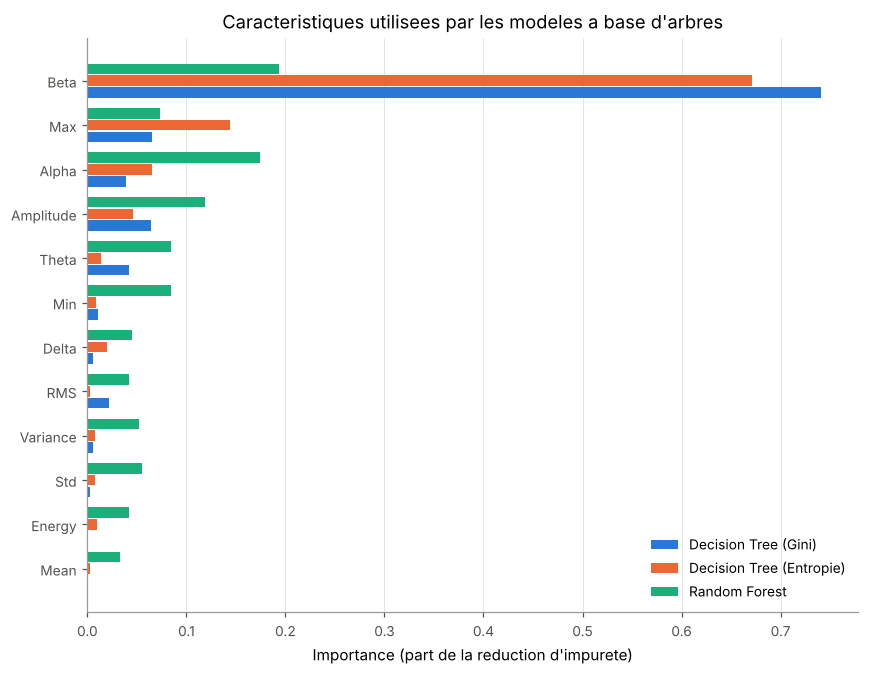

In [48]:
fig = plot_feature_importances(tuned, ["Decision Tree (Gini)", "Decision Tree (Entropie)", "Random Forest"], FEATURES)
save("q12_5_importances")

* Les deux arbres font presque tout avec **Beta** (environ 70 % de l'importance), puis Max,
  Amplitude et Alpha. Pourtant Beta n'était pas la meilleure variable seule (AUC 0,93, Question 11) :
  c'est la meilleure **première question**, car elle sépare les crises des artefacts lents, et les
  autres variables corrigent ensuite.
* Les variables redondantes (Std, RMS, Variance, Energy) ne sont presque pas utilisées par les
  arbres : quand Amplitude ou Max est déjà choisie, elles n'apportent plus rien. Cela confirme
  la Question 11.
* La forêt répartit l'importance sur plus de variables (Beta, Alpha, Amplitude, Theta, Min), car
  chaque arbre ne voit qu'une partie des variables à chaque nœud. **Mean** reste la moins utile.

## Partie IX : Évaluation des modèles

Chaque modèle prédit les 5 799 fenêtres de test, jamais vues pendant l'entraînement ni pendant
le choix des hyperparamètres. La classe positive est **1 = crise** :

* **Precision** : parmi les fenêtres annoncées « crise », la part de vraies crises (peu de fausses alarmes) ;
* **Recall** : parmi les vraies fenêtres de crise, la part détectée (peu de crises manquées) ;
* **F1-score** : moyenne harmonique des deux ; il n'est élevé que si les deux le sont.

,Accuracy,Precision,Recall,F1-score
Modele,,,,
Random Forest,0.984,0.872,0.720,0.789
Gradient Boosting,0.982,0.830,0.703,0.761
SVM (RBF),0.982,0.838,0.678,0.749
Decision Tree (Entropie),0.980,0.808,0.678,0.737
KNN,0.980,0.784,0.691,0.734
Decision Tree (Gini),0.979,0.782,0.682,0.729
Reference : toujours 0,0.959,0.000,0.000,0.000


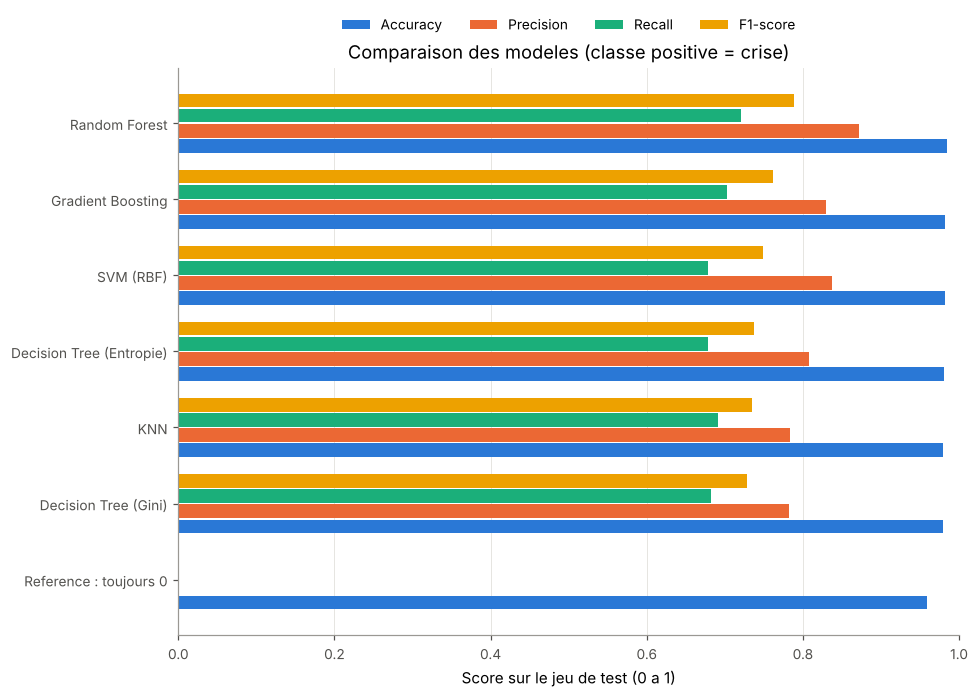

In [49]:
results = results_table(tuned, X_test, y_test)
display(results[["Accuracy", "Precision", "Recall", "F1-score"]].round(3))

fig = plot_metric_comparison(results)
save("q12_6_comparaison_modeles")

,VP (crise detectee),FN (crise manquee),FP (fausse alarme),VN
Modele,,,,
Decision Tree (Gini),161,75,45,5518
Decision Tree (Entropie),160,76,38,5525
Random Forest,170,66,25,5538
KNN,163,73,45,5518
SVM (RBF),160,76,31,5532
Gradient Boosting,166,70,34,5529
Reference : toujours 0,0,236,0,5563


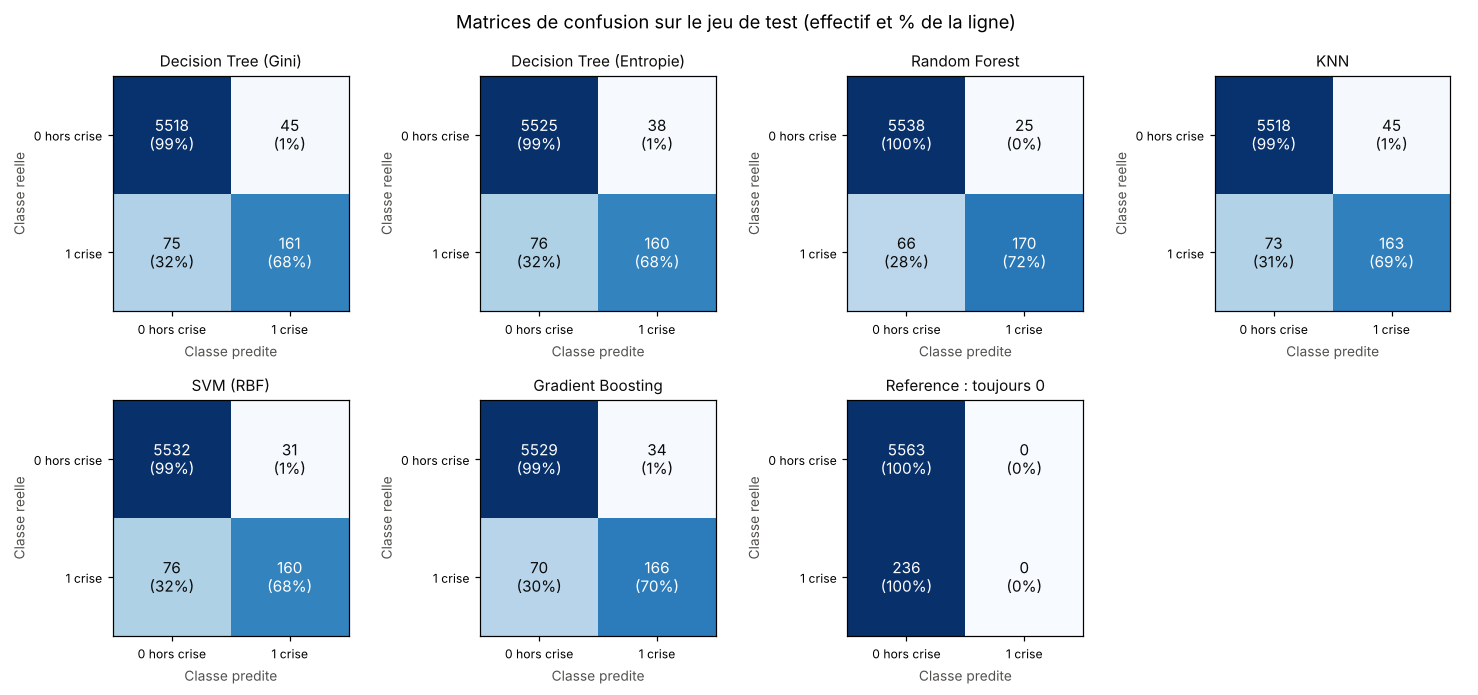

In [50]:
display(confusion_table(tuned, X_test, y_test))
fig = plot_confusion_matrices(tuned, X_test, y_test)
save("q12_7_matrices_confusion")

**Lecture des résultats**

* **L'accuracy ne départage rien** : tous les modèles sont entre 97,9 % et 98,4 %, et la
  référence qui répond toujours « pas de crise » atteint déjà **95,9 %** sans détecter une seule
  crise (Recall = 0). C'est l'illustration directe de la Question 13.
* **La Random Forest est la meilleure** sur toutes les métriques : F1 = 0,79, Precision = 0,87,
  Recall = 0,72. Elle détecte 170 des 236 fenêtres de crise du test, avec seulement 25 fausses
  alarmes sur 5 563 fenêtres normales.
* Le **Gradient Boosting** (modèle proposé) est deuxième (F1 = 0,76), puis le SVM (0,75).
* Les deux **arbres seuls** et le **KNN** sont un peu en dessous (F1 ≈ 0,73) : un arbre unique
  est instable, et le KNN souffre des différences d'amplitude entre patients.
* Tous les modèles ont une **Precision plus haute que le Recall** : quand ils annoncent une crise,
  ils ont presque toujours raison, mais ils en manquent environ 30 %. Les fenêtres manquées sont
  surtout les fenêtres de **bord de crise** (50 à 70 % d'échantillons en crise), les crises très
  courtes et le patient `230718A-A` au niveau de base élevé. Pour un usage médical, où rater une
  crise coûte plus cher qu'une fausse alarme, il faudrait favoriser le Recall (Question 13 et Partie XII).

### Contrôle : généralisation à un nouvel enregistrement

La séparation demandée (80/20 aléatoire) mélange les fenêtres d'un même enregistrement entre
l'entraînement et le test. Or deux fenêtres voisines partagent 50 % de leurs échantillons : le
modèle a donc déjà vu « presque » chaque fenêtre de test. Les scores ci-dessus sont **optimistes**.

Pour mesurer la situation réelle (un nouveau patient), on refait l'évaluation avec une
**validation croisée par enregistrement** (`GroupKFold`, 5 plis) : toutes les fenêtres d'un
enregistrement sont soit en entraînement, soit en test. Les hyperparamètres sont ceux trouvés
plus haut.

In [51]:
groups_eval = group_evaluation(tuned, dataset[FEATURES], dataset["Class"], dataset["recording_id"])
display(groups_eval.round(3))

,Accuracy,Precision,Recall,F1-score,F1 par pli (min-max)
Modele,,,,,
KNN,0.977,0.760,0.655,0.703,0.63 - 0.78
SVM (RBF),0.977,0.770,0.636,0.697,0.63 - 0.75
Random Forest,0.977,0.760,0.634,0.691,0.61 - 0.77
Gradient Boosting,0.974,0.696,0.625,0.659,0.49 - 0.78
Decision Tree (Entropie),0.966,0.577,0.591,0.584,0.29 - 0.71
Decision Tree (Gini),0.954,0.451,0.617,0.521,0.19 - 0.72
Reference : toujours 0,0.959,0.000,0.000,0.000,0.00 - 0.00


* Sur des **patients jamais vus**, tous les F1 baissent : **0,70 pour le KNN, 0,70 pour le SVM,
  0,69 pour la Random Forest**, contre 0,73 à 0,79 avec la séparation aléatoire. L'écart mesure
  la part d'optimisme due aux fenêtres voisines.
* Le classement change : les modèles qui lissent le plus (KNN, SVM, forêt) résistent bien ;
  les **arbres seuls s'effondrent** (F1 de 0,52 à 0,58, et jusqu'à 0,19 sur un pli). Un arbre
  apprend des seuils d'amplitude précis, qui ne valent pas pour un patient dont le niveau de base
  est différent.
* Les résultats varient beaucoup d'un pli à l'autre (colonne min-max) : la difficulté dépend du patient.

## Question 13 : quelle métrique privilégier ?

On compare trois modèles « idiots » à la Random Forest, sur nos 28 994 fenêtres (4,1 % de crises) :

In [52]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_all = dataset["Class"].to_numpy()
rng = np.random.default_rng(RANDOM_STATE)
naive = {
    "Toujours 0 (jamais de crise)": np.zeros_like(y_all),
    "Toujours 1 (crise partout)": np.ones_like(y_all),
    "Au hasard (4 % de 1)": (rng.random(y_all.size) < y_all.mean()).astype(int),
}
rows = {}
for name, pred in naive.items():
    rows[name] = {"Accuracy": accuracy_score(y_all, pred),
                  "Precision": precision_score(y_all, pred, zero_division=0),
                  "Recall": recall_score(y_all, pred), "F1-score": f1_score(y_all, pred)}
rows["Random Forest (test 80/20)"] = results.loc["Random Forest", ["Accuracy", "Precision", "Recall", "F1-score"]].to_dict()
display(pd.DataFrame(rows).T.round(3))

,Accuracy,Precision,Recall,F1-score
Toujours 0 (jamais de crise),0.959,0.000,0.000,0.000
Toujours 1 (crise partout),0.041,0.041,1.000,0.078
Au hasard (4 % de 1),0.922,0.045,0.046,0.045
Random Forest (test 80/20),0.984,0.872,0.720,0.789


**Pourquoi l'accuracy seule est trompeuse.** L'accuracy compte toutes les bonnes réponses, et
96 % des bonnes réponses possibles sont des fenêtres *sans* crise. Le modèle « toujours 0 » obtient
donc **95,9 %** d'accuracy sans détecter une seule crise, et un modèle au hasard dépasse encore
92 %. Entre nos vrais modèles, l'accuracy ne varie que de 97,9 % à 98,4 % (Partie IX) : elle ne
permet ni de juger ni de départager. Plus les classes sont déséquilibrées, plus l'accuracy reflète
la classe majoritaire au lieu de la classe qui nous intéresse.

**Ce que mesure chaque métrique (classe positive = crise) :**

| Métrique | Question posée | Erreur pénalisée |
| --- | --- | --- |
| Precision | Quand le modèle annonce une crise, a-t-il raison ? | fausses alarmes (FP) |
| Recall (sensibilité) | Parmi les vraies crises, combien sont trouvées ? | crises manquées (FN) |
| F1-score | Compromis : moyenne harmonique Precision / Recall | les deux |

**Notre choix : le Recall en priorité, contrôlé par le F1.**

* Dans un système de surveillance, **rater une crise** (FN) est l'erreur la plus grave : le
  diagnostic ou l'alerte n'a pas lieu. Le **Recall** est donc la métrique principale.
* Mais le Recall seul se triche aussi : « toujours 1 » a un Recall de 1 avec une Precision de
  4 %. Trop de fausses alarmes et le personnel finit par ignorer le système. On surveille donc la
  **Precision**, et on résume les deux par le **F1-score**, qui ne peut être élevé que si les deux
  le sont. C'est le critère utilisé pour régler tous les modèles (`GridSearchCV`, Partie VIII).
* Pour une application réelle, on complète par deux mesures **par crise** plutôt que par fenêtre
  (Partie X) : la part des crises détectées et le **nombre de fausses alarmes par heure**.

## Partie X : détection temporelle des crises

### Méthode

Le modèle (Random Forest, meilleur modèle de la Partie IX) donne une classe par fenêtre de 2 s.
Pour retrouver des crises dans le temps :

1. **Prédire chaque fenêtre sans avoir vu son enregistrement.** Le test 80/20 tire les fenêtres au
   hasard : il ne garde qu'une fenêtre sur cinq par enregistrement, on ne peut pas y reconstruire
   une crise continue. On utilise donc la validation par enregistrement (`GroupKFold`, 5 plis) :
   chaque enregistrement est prédit par une forêt entraînée sur les 4/5 *autres*. Toutes les
   fenêtres deviennent des fenêtres de test, comme pour un nouveau patient.
2. **Regrouper les fenêtres consécutives prédites 1** en un intervalle. Les fenêtres se
   chevauchent (pas de 1 s) : on attribue à chaque fenêtre sa seconde centrale. Une suite de
   fenêtres prédites crise de la fenêtre *a* à la fenêtre *b* donne l'intervalle
   [début(a) + 0,5 s ; début(b) + 1,5 s].
3. **Comparer aux annotations** : une crise réelle est *détectée* si un intervalle prédit la
   chevauche ; un intervalle prédit qui ne chevauche aucune crise est une *fausse alarme*.

Le même calcul prépare aussi la Partie XII (choix du seuil en validation interne) : il prend
environ 3 minutes.

In [53]:
from src.detection import (out_of_fold_proba, predictions_to_intervals, detected_intervals,
                           match_events, event_summary, interval_table, plot_detection, plot_detection_zoom)
from src.improvement import nested_threshold_predictions

BEST = "Random Forest"
best_estimator = tuned[BEST].estimator
groups = dataset["recording_id"]

# Une seule passe pour les Parties X, XI et XII : dans chaque pli (par enregistrement),
# le modele predit les enregistrements qu'il n'a jamais vus ; le seuil de la Partie XII
# est choisi par une validation interne sur les seuls enregistrements d'entrainement.
nested = nested_threshold_predictions(best_estimator, dataset[FEATURES], dataset["Class"], groups,
                                      smoothing_sizes=(1, 3))

windows_pred = dataset[["recording_id", "window", "start_s", "end_s", "crisis_fraction", "Class"] + FEATURES].copy()
windows_pred["proba"] = nested["proba"]
windows_pred["pred"] = (windows_pred["proba"] >= 0.5).astype(int)   # seuil par defaut

print(f"Fenetres predites : {len(windows_pred)} (toutes, chacune par un modele qui n'a pas vu son enregistrement)")

pli 1 : seuils choisis en validation interne -> lissage 1 : 0.35, lissage 3 : 0.35


pli 2 : seuils choisis en validation interne -> lissage 1 : 0.40, lissage 3 : 0.35


pli 3 : seuils choisis en validation interne -> lissage 1 : 0.40, lissage 3 : 0.35


pli 4 : seuils choisis en validation interne -> lissage 1 : 0.35, lissage 3 : 0.30


pli 5 : seuils choisis en validation interne -> lissage 1 : 0.45, lissage 3 : 0.30
Fenetres predites : 28994 (toutes, chacune par un modele qui n'a pas vu son enregistrement)


### Question 14 : intervalles détectés et comparaison avec les annotations

Enregistrement de démonstration `230102B_F` (9 crises), seuil par défaut 0,5 :

In [54]:
intervals_demo = detected_intervals(windows_pred, "pred")[RECORDING_ID]
true_demo = seizure_intervals(annotations, RECORDING_ID)

print(f"{RECORDING_ID} : crises detectees par la Random Forest")
for k, (a, b) in enumerate(intervals_demo, start=1):
    print(f"  Crise detectee {k} : {a:6.1f} s -> {b:6.1f} s")

per_true, per_det = match_events(true_demo, intervals_demo)
print("\nComparaison avec les annotations (une ligne par crise reelle) :")
display(per_true.round(1))
print("Intervalles predits (fausses alarmes = aucune crise reelle chevauchee) :")
display(per_det.round(1))

230102B_F_0000 : crises detectees par la Random Forest
  Crise detectee 1 :    0.5 s ->    1.5 s
  Crise detectee 2 :   15.5 s ->   17.5 s
  Crise detectee 3 :   59.5 s ->   67.5 s
  Crise detectee 4 :  231.5 s ->  246.5 s
  Crise detectee 5 :  267.5 s ->  268.5 s
  Crise detectee 6 :  274.5 s ->  275.5 s
  Crise detectee 7 :  277.5 s ->  283.5 s
  Crise detectee 8 :  331.5 s ->  332.5 s
  Crise detectee 9 :  338.5 s ->  340.5 s
  Crise detectee 10 :  374.5 s ->  386.5 s
  Crise detectee 11 :  454.5 s ->  462.5 s
  Crise detectee 12 :  642.5 s ->  660.5 s
  Crise detectee 13 :  841.5 s ->  842.5 s
  Crise detectee 14 :  945.5 s ->  947.5 s
  Crise detectee 15 :  955.5 s ->  956.5 s
  Crise detectee 16 :  960.5 s ->  962.5 s
  Crise detectee 17 :  964.5 s ->  977.5 s
  Crise detectee 18 : 1058.5 s -> 1075.5 s
  Crise detectee 19 : 1206.5 s -> 1220.5 s

Comparaison avec les annotations (une ligne par crise reelle) :


,crise,debut reel (s),fin reelle (s),duree (s),detectee,debut detecte (s),fin detectee (s),retard au debut (s),ecart a la fin (s),part couverte (%),morceaux
0,1,58.0,67.0,9.0,True,59.5,67.5,1.5,0.5,83.3,1
1,2,230.0,246.0,16.0,True,231.5,246.5,1.5,0.5,90.6,1
2,3,277.0,287.0,10.0,True,277.5,283.5,0.5,-3.5,60.0,1
3,4,373.0,387.0,14.0,True,374.5,386.5,1.5,-0.5,85.7,1
4,5,454.0,462.0,8.0,True,454.5,462.5,0.5,0.5,93.8,1
5,6,641.0,661.0,20.0,True,642.5,660.5,1.5,-0.5,90.0,1
6,7,956.0,980.0,24.0,True,955.5,977.5,-0.5,-2.5,64.6,3
7,8,1058.0,1075.0,17.0,True,1058.5,1075.5,0.5,0.5,97.1,1
8,9,1203.0,1220.0,17.0,True,1206.5,1220.5,3.5,0.5,79.4,1


Intervalles predits (fausses alarmes = aucune crise reelle chevauchee) :


,detection,debut (s),fin (s),duree (s),crise reelle,fausse alarme
0,1,0.5,1.5,1.0,aucune,True
1,2,15.5,17.5,2.0,aucune,True
2,3,59.5,67.5,8.0,1,False
3,4,231.5,246.5,15.0,2,False
4,5,267.5,268.5,1.0,aucune,True
5,6,274.5,275.5,1.0,aucune,True
6,7,277.5,283.5,6.0,3,False
7,8,331.5,332.5,1.0,aucune,True
8,9,338.5,340.5,2.0,aucune,True
9,10,374.5,386.5,12.0,4,False


**Lecture**

* Les **9 crises sont détectées**. Le début détecté arrive en général **0,5 à 1,5 s après** le
  début annoté, et la fin à ±0,5 s : c'est la résolution des fenêtres (1 s).
* Les intervalles couvrent 60 à 97 % de la durée réelle. La crise 7 (24 s) est coupée en
  **3 morceaux** : le modèle « décroche » quelques secondes au milieu de la crise.
* Il y a **8 fausses alarmes**, presque toutes très courtes (1 à 2 s, une ou deux fenêtres
  isolées). C'est le défaut principal du système brut.

**Signal EEG, crises réelles et crises prédites**

En haut le signal filtré (Fp1) avec les crises annotées en orange ; au milieu la probabilité de
crise donnée par la forêt ; en bas les intervalles réels et prédits.

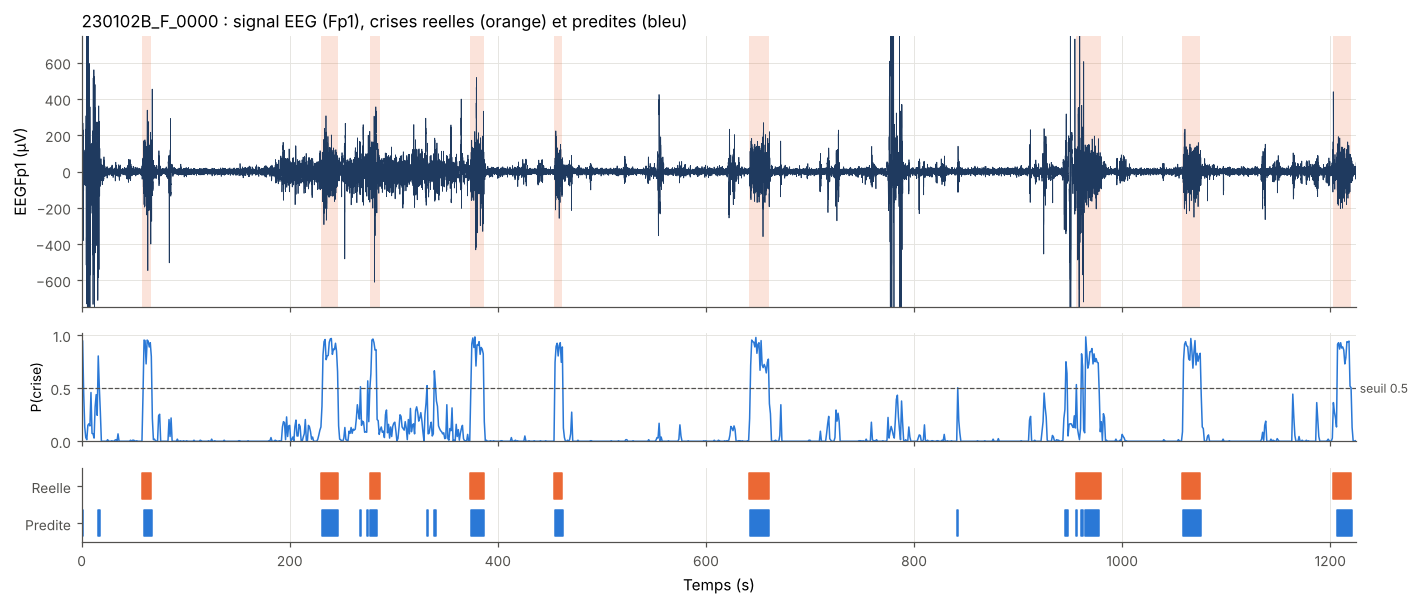

In [55]:
demo_part = windows_pred[windows_pred["recording_id"] == RECORDING_ID].sort_values("start_s")
fig = plot_detection(clean, "EEGFp1", true_demo, intervals_demo,
                     proba=demo_part["proba"].to_numpy(), proba_time=demo_part["start_s"].to_numpy() + 1,
                     threshold=0.5,
                     title=f"{RECORDING_ID} : signal EEG (Fp1), crises reelles (orange) et predites (bleu)")
save("q14_1_detection_enregistrement")

Zoom sur la première crise, sur 5 électrodes de l'hémisphère gauche (de l'avant vers l'arrière) :
la décharge pointe-onde à 3 Hz apparaît en même temps sur tous les canaux, et la détection
commence une seconde après le début annoté.

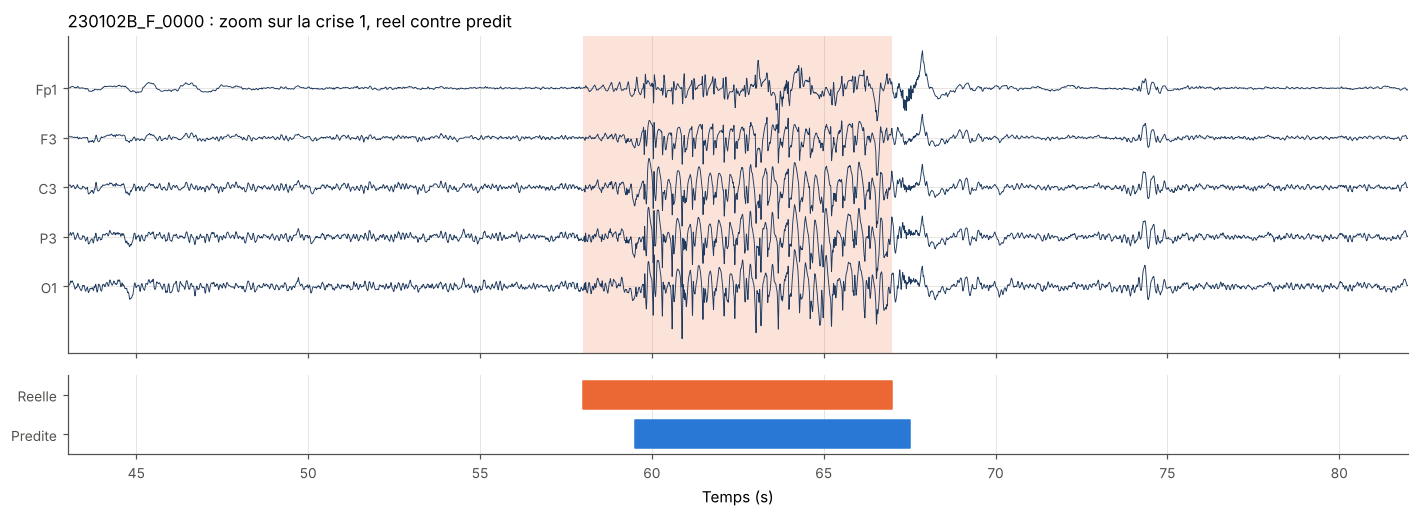

In [56]:
first = true_demo[0]
fig = plot_detection_zoom(clean, ["EEGFp1", "EEGF3", "EEGC3", "EEGP3", "EEGO1"], true_demo, intervals_demo,
                          start=first[0] - 15, end=first[1] + 15,
                          title=f"{RECORDING_ID} : zoom sur la crise 1, reel contre predit")
save("q14_2_detection_zoom")

**Bilan sur les 19 enregistrements** (chaque enregistrement prédit par un modèle qui ne l'a jamais vu) :

In [57]:
events_base = event_summary(windows_pred, "pred", annotations)
display(events_base)

,crises reelles,crises detectees,intervalles predits,fausses alarmes,duree (h),retard median (s),sensibilite (%),fausses alarmes / h
enregistrement,,,,,,,,
190304A-E,1.0,1.0,3.0,1.0,0.44,0.5,100.0,2.27
191113A-D,2.0,0.0,0.0,0.0,0.50,NaN,0.0,0.00
210406A-F,1.0,1.0,1.0,0.0,0.40,2.5,100.0,0.00
210427B-C,1.0,1.0,23.0,20.0,0.35,0.5,100.0,57.14
210504B-C,12.0,12.0,37.0,23.0,0.87,0.5,100.0,26.44
210914B-A,11.0,11.0,29.0,6.0,0.33,0.5,100.0,18.18
210928B-B,2.0,2.0,5.0,0.0,0.37,1.0,100.0,0.00
211027B-C,8.0,8.0,15.0,5.0,0.35,1.5,100.0,14.29
211104B-D,5.0,5.0,7.0,2.0,0.34,0.5,100.0,5.88


* **81 crises sur 83 sont détectées (97,6 %)**, avec un retard médian au début de 0,5 à 1,5 s.
  Au niveau des crises, le système est donc bien plus fiable que ne le laisse penser le Recall
  par fenêtre (0,64) : il manque surtout des *morceaux* de crises, rarement des crises entières.
* Les 2 crises manquées sont celles de `191113A-D`, dont le niveau de base est atypique (Partie XI).
* Le vrai problème est le nombre de **fausses alarmes : 87 en 8 h, soit 10,8 par heure**, très
  concentrées sur quelques enregistrements (`210427B-C` : 57 par heure, `210504B-C` : 26 par heure).

## Partie XI : analyse des erreurs

On classe chaque fenêtre (prédictions de la Partie X, Random Forest, seuil 0,5) :

* **VP** : crise prédite crise ; **VN** : hors crise prédite hors crise ;
* **FN** : crise prédite hors crise (crise manquée) ; **FP** : hors crise prédite crise (fausse alarme).

In [58]:
from src.errors import (error_types, error_counts, add_error_context, false_negative_profile,
                        false_positive_profile, errors_by_recording, plot_error_analysis)

windows_pred["type"] = error_types(windows_pred["Class"], windows_pred["pred"])
windows_pred = add_error_context(windows_pred, annotations)
display(error_counts(windows_pred["type"]))

,type,fenetres,part (%)
VP,Vrai positif (crise detectee),753,2.60
FN,Faux negatif (crise manquee),429,1.48
FP,Faux positif (fausse alarme),240,0.83
VN,Vrai negatif,27572,95.10


Les erreurs ne représentent que 2,3 % des fenêtres, mais **36 % des fenêtres de crise sont
manquées** (429 FN pour 753 VP) et **24 % des alarmes sont fausses** (240 FP).
On cherche maintenant *où* se trouvent ces erreurs.

fenetres de crise  manquees (FN)  taux de FN (%)
critere                     groupe                                                          
part de la fenetre en crise 50-75 % (bord)                165            121            73.3
                            100 % (coeur)                1017            308            30.3
duree de la crise           < 5 s                          61             24            39.3
                            5-10 s                        248             65            26.2
                            10-20 s                       505            157            31.1
                            > 20 s                        368            183            49.7

,fenetres hors crise,fausses alarmes (FP),taux de FP (%),part des FP (%)
position de la fenetre,,,,
touche une crise (< 50 %),165,2,1.21,0.8
a moins de 10 s d'une crise,1540,7,0.45,2.9
loin de toute crise,26107,231,0.88,96.2


type,VP,FN,FP,VN,Recall (%),Precision (%)
recording_id,,,,,,
210504B-C,78,68,75,2899,53.4,51.0
210427B-C,14,5,57,1169,73.7,19.7
211027B-C,111,20,28,1095,84.7,79.9
230210B-D,22,1,16,1133,95.7,57.9
230718A-A,61,13,14,1117,82.4,81.3
211104B-D,35,10,11,1153,77.8,76.1
230102B-F,114,30,11,1069,79.2,91.2
210914B-A,88,99,8,1009,47.1,91.7


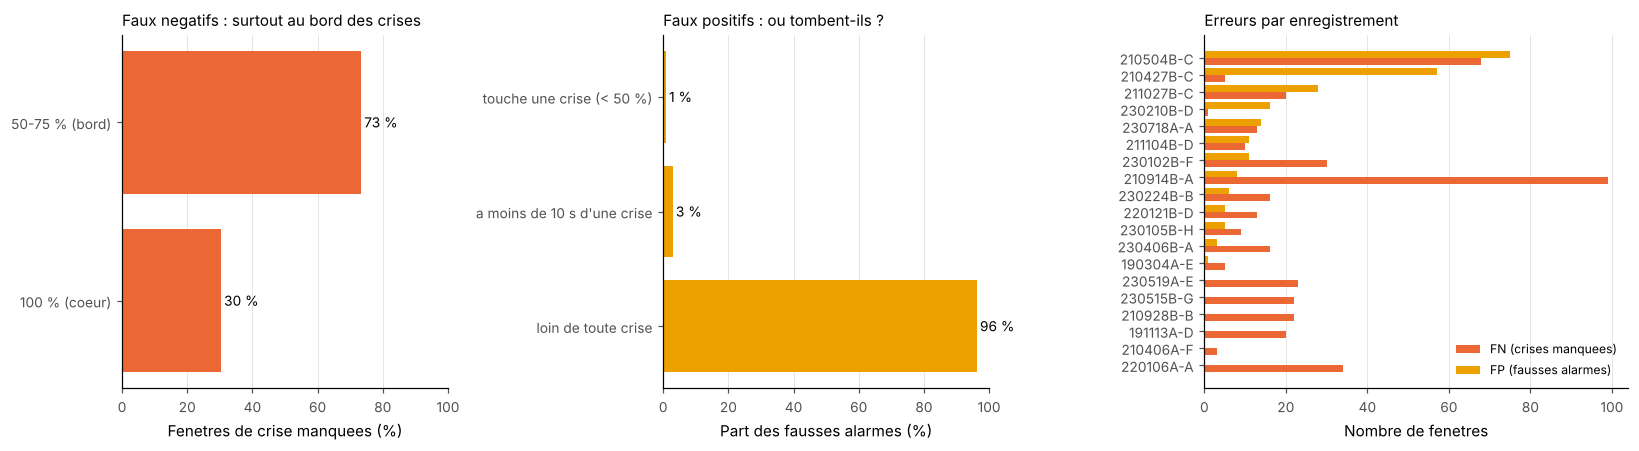

In [59]:
fn_profile = false_negative_profile(windows_pred)
fp_profile = false_positive_profile(windows_pred)
by_recording = errors_by_recording(windows_pred)
display(fn_profile)
display(fp_profile)
display(by_recording.head(8))

fig = plot_error_analysis(fn_profile, fp_profile, by_recording)
save("q15_1_analyse_erreurs")

**Faux négatifs (crises manquées)**

* **Les bords de crise** : une fenêtre qui n'est qu'à 50 à 75 % en crise est manquée 3 fois
  sur 4 (73 %), contre 30 % pour une fenêtre entièrement en crise. Ces fenêtres mélangent
  activité normale et pointes-ondes : leurs caractéristiques sont entre les deux classes. C'est
  aussi pourquoi le début détecté arrive environ 1 s après le début annoté.
* **Les crises longues** (> 20 s) sont plus souvent manquées (50 %) : l'amplitude des
  pointes-ondes baisse au cours de la crise, et le milieu passe sous le seuil (crise 7 de
  `230102B_F` coupée en 3).
* **Certains patients** : `191113A-D` (0 fenêtre de crise sur 20 trouvée) et `220106A-A`
  (13 %) ont des crises de faible amplitude par rapport à leur niveau de base. Un modèle appris
  sur les autres patients n'y reconnaît pas la crise.

**Faux positifs (fausses alarmes)**

* **96 % des fausses alarmes sont loin de toute crise** : ce ne sont pas des erreurs de bord
  mais de vraies confusions avec autre chose.
* Elles sont **concentrées** : `210504B-C` et `210427B-C` regroupent 55 % des FP. Dans ces
  enregistrements, des artefacts de grande amplitude (mouvements, clignements, électrode qui
  bouge) ressemblent à une crise pour des variables qui mesurent surtout l'amplitude.
* Elles sont **courtes** : la plupart durent une ou deux fenêtres, alors qu'une crise d'absence
  dure au moins 2 s et souvent plus de 5 s.

**Profil des fenêtres selon le type d'erreur** (médianes) :

In [60]:
profile = (windows_pred.groupby("type")[["Amplitude", "Std", "Delta", "Theta", "Beta"]]
           .median().reindex(["VN", "FP", "FN", "VP"]).round(1))
profile.insert(0, "fenetres", windows_pred["type"].value_counts().reindex(profile.index))
display(profile)

,fenetres,Amplitude,Std,Delta,Theta,Beta
type,,,,,,
VN,27572,105.0,20.6,214.8,65.5,13.6
FP,240,550.1,120.8,10119.9,1160.3,519.6
FN,429,380.6,74.4,3338.7,508.5,45.3
VP,753,689.1,154.4,16267.5,2075.0,837.4


* Les **FP** ont une amplitude et des puissances bien plus grandes que les VN, proches des vraies
  crises : le modèle a raison de « s'inquiéter », ce sont des fenêtres anormales. Ce qui les
  distingue d'une crise est la forme du signal (rythme régulier à 3 Hz ou non), que nos
  variables résument mal.
* Les **FN** ont des valeurs intermédiaires entre VN et VP : ce sont des crises « faibles » ou
  des bords de crise.

**Un exemple de chaque cas** (signal Fp1, la fenêtre de 2 s en couleur, les crises annotées en
trait orange en bas) :

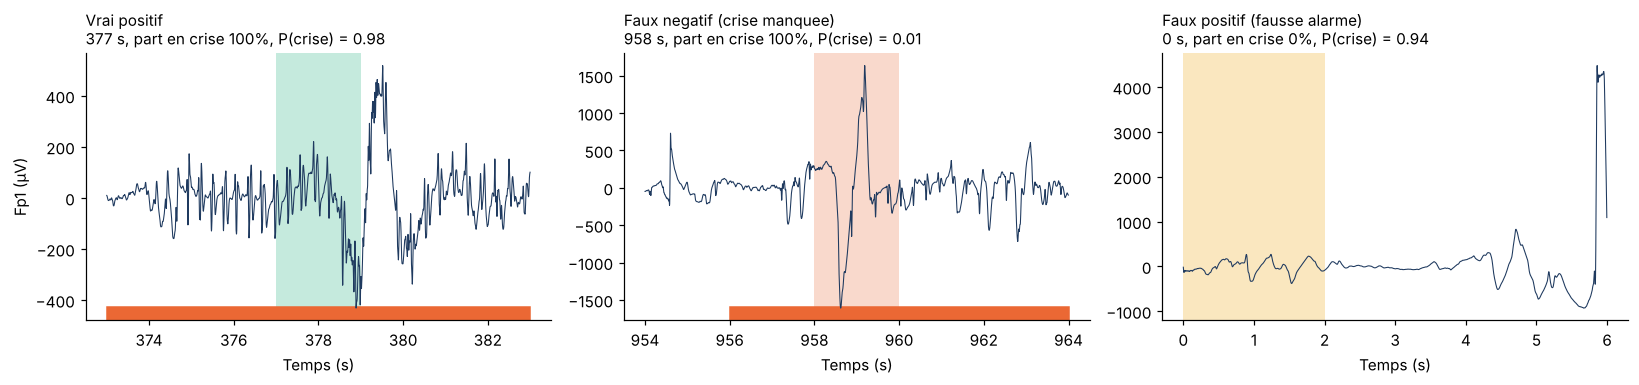

In [61]:
# Exemples pris dans l'enregistrement de demonstration : le meilleur vrai positif, la fenetre
# entierement en crise la plus nettement manquee, et la fausse alarme la plus "sure" d'elle.
demo_rows = windows_pred[windows_pred["recording_id"] == RECORDING_ID]
examples = [
    ("Vrai positif", demo_rows[demo_rows["type"] == "VP"].sort_values("proba", ascending=False).iloc[0], "#1baf7a"),
    ("Faux negatif (crise manquee)",
     demo_rows[(demo_rows["type"] == "FN") & (demo_rows["crisis_fraction"] == 1)].sort_values("proba").iloc[0], "#eb6834"),
    ("Faux positif (fausse alarme)", demo_rows[demo_rows["type"] == "FP"].sort_values("proba", ascending=False).iloc[0], "#eda100"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (label, row, color) in zip(axes, examples):
    t0 = row["start_s"]
    seg = clean.window(t0 - 4, t0 + 6)
    ax.plot(seg["Time"], seg["EEGFp1"], color="#1f3a5f", linewidth=0.7)
    ax.axvspan(t0, t0 + 2, color=color, alpha=0.25, linewidth=0)
    for a, b in true_demo:
        if b > t0 - 4 and a < t0 + 6:
            ax.axvspan(max(a, t0 - 4), min(b, t0 + 6), ymin=0, ymax=0.05, color="#eb6834")
    ax.set_title(f"{label}\n{t0:.0f} s, part en crise {row['crisis_fraction']:.0%}, P(crise) = {row['proba']:.2f}",
                 fontsize=10, loc="left")
    ax.set_xlabel("Temps (s)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Fp1 (µV)")
save("q15_2_exemples_erreurs")

* **Vrai positif** (377 s) : pointes-ondes régulières, amplitude élevée sur toute la fenêtre.
* **Faux négatif** (958 s, au milieu de la crise 7) : un très grand artefact (environ 1 500 µV,
  probablement un mouvement) se superpose à la crise. Aucune crise de l'entraînement n'a ce profil :
  la forêt répond « hors crise ». C'est ce qui coupe la crise 7 en 3 morceaux.
* **Faux positif** (0 s) : le tout début de l'enregistrement, pendant que le tracé se stabilise
  (mise en place, effet de bord du filtrage). Un artefact classique, qu'on pourrait exclure en
  ignorant les premières secondes de chaque tracé.


**Bilan de l'analyse des erreurs**

| Erreur | Cause principale | Piste (Partie XII) |
| --- | --- | --- |
| FN au bord des crises | fenêtre à moitié en crise | regarder les fenêtres voisines (contexte, lissage) |
| FN dans les crises longues | la crise « décroche » quelques secondes | combler les trous courts |
| FN chez certains patients | amplitude de crise faible pour ce patient | normalisation par enregistrement |
| FP isolés loin des crises | artefacts brefs de grande amplitude | lissage, durée minimale de 2 s |
| Trop peu de crises trouvées (Recall) | seuil 0,5 trop strict pour une classe rare | baisser le seuil de décision |

## Partie XII : amélioration du système

Chaque piste vient de l'analyse des erreurs. Toutes sont mesurées de la même façon :
**validation par enregistrement** (patients jamais vus), en **F1 par fenêtre** et en
**crises détectées / fausses alarmes par heure**. La référence est la Random Forest au seuil 0,5
(Partie X).

### 1. Seuil de décision et lissage temporel

* **Seuil** : par défaut une fenêtre est « crise » si P(crise) ≥ 0,5. Avec 4 % de crises, ce
  seuil est trop strict (Recall 0,64). Le seuil est choisi **en validation interne** : dans chaque
  pli, une seconde validation croisée sur les seuls enregistrements d'entraînement donne le seuil
  qui maximise le F1. Le pli de test n'intervient jamais dans ce choix.
* **Lissage** : on remplace la probabilité d'une fenêtre par la moyenne sur elle et ses deux
  voisines. Une fenêtre isolée à forte probabilité (artefact) est atténuée ; une crise, qui dure,
  ne l'est pas.

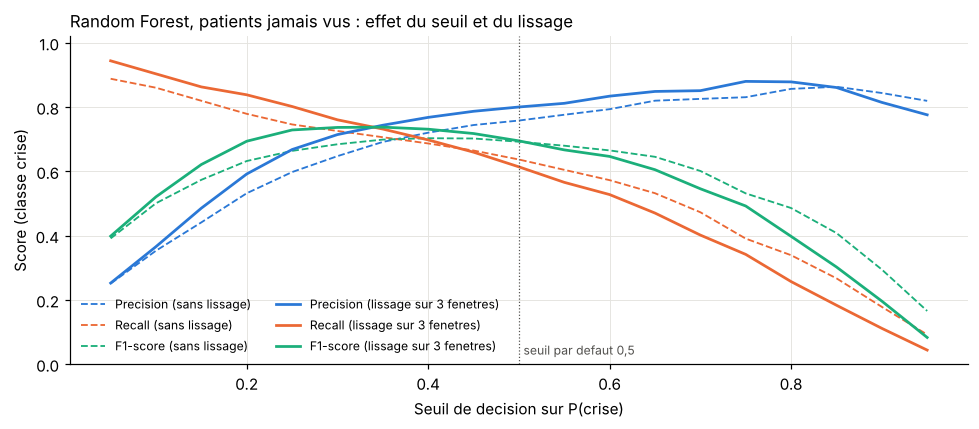

Seuils choisis en validation interne, par pli :
  sans lissage : [0.35, 0.4, 0.4, 0.35, 0.45]
  avec lissage : [0.35, 0.35, 0.35, 0.3, 0.3]


In [62]:
from src.improvement import (add_context_features, add_recording_normalization, plain_predictions,
                             window_and_event_metrics, threshold_curve, plot_threshold_curve, plot_improvements)
from src.detection import smooth_proba, postprocess

curves = {
    "sans lissage": threshold_curve(windows_pred["Class"], windows_pred["proba"]),
    "lissage sur 3 fenetres": threshold_curve(windows_pred["Class"], smooth_proba(windows_pred["proba"], groups, 3)),
}
fig = plot_threshold_curve(curves)
save("q16_1_seuil_lissage")
print("Seuils choisis en validation interne, par pli :")
print("  sans lissage :", nested[1]["thresholds"])
print("  avec lissage :", nested[3]["thresholds"])

* Sans lissage (pointillés), baisser le seuil fait monter le Recall mais la Precision chute vite.
* Avec le lissage (traits pleins), la Precision tient beaucoup mieux : le F1 maximal monte et le
  meilleur seuil descend vers **0,30 à 0,35**. Les seuils choisis en validation interne sont stables
  d'un pli à l'autre.

### 2. Autres pistes testées, puis comparaison

* **A. Contexte temporel** : on ajoute pour chaque variable sa moyenne sur 3 et sur 5 fenêtres
  voisines (36 variables au lieu de 12).
* **B. Normalisation par enregistrement** : chaque variable est exprimée par rapport à sa
  médiane chez le patient, plus les puissances relatives (Delta / puissance totale, etc.).
* **C. Déséquilibre des classes** : `class_weight = balanced_subsample` dans la forêt.
* **F. Règles de durée** : après seuil et lissage, on comble un trou d'une fenêtre au milieu d'une
  détection et on supprime une détection d'une seule fenêtre (1 s, plus court que la plus courte
  crise annotée, 2 s). Ces règles viennent du domaine, elles ne sont pas réglées sur les données.

Les variantes A, B, C prennent environ 2 minutes.

Variantes A, B, C : 284 s


,Accuracy,Precision,Recall,F1-score,crises detectees,sensibilite crises (%),fausses alarmes,fausses alarmes / h
"Base : Random Forest, seuil 0,5",0.977,0.758,0.637,0.692,81/83,97.600000,87,10.800000
A. + contexte temporel (36 variables),0.977,0.729,0.702,0.715,78/83,94.000000,59,7.320000
B. + normalisation par enregistrement,0.976,0.735,0.637,0.682,80/83,96.400000,79,9.800000
C. + poids des classes equilibres,0.976,0.700,0.699,0.699,82/83,98.800000,133,16.500000
D. seuil choisi en validation interne,0.976,0.713,0.685,0.699,81/83,97.600000,130,16.130000
E. seuil + lissage temporel,0.978,0.730,0.742,0.736,81/83,97.600000,55,6.820000
F. E + regles de duree (retenu),0.979,0.737,0.745,0.741,81/83,97.600000,42,5.210000


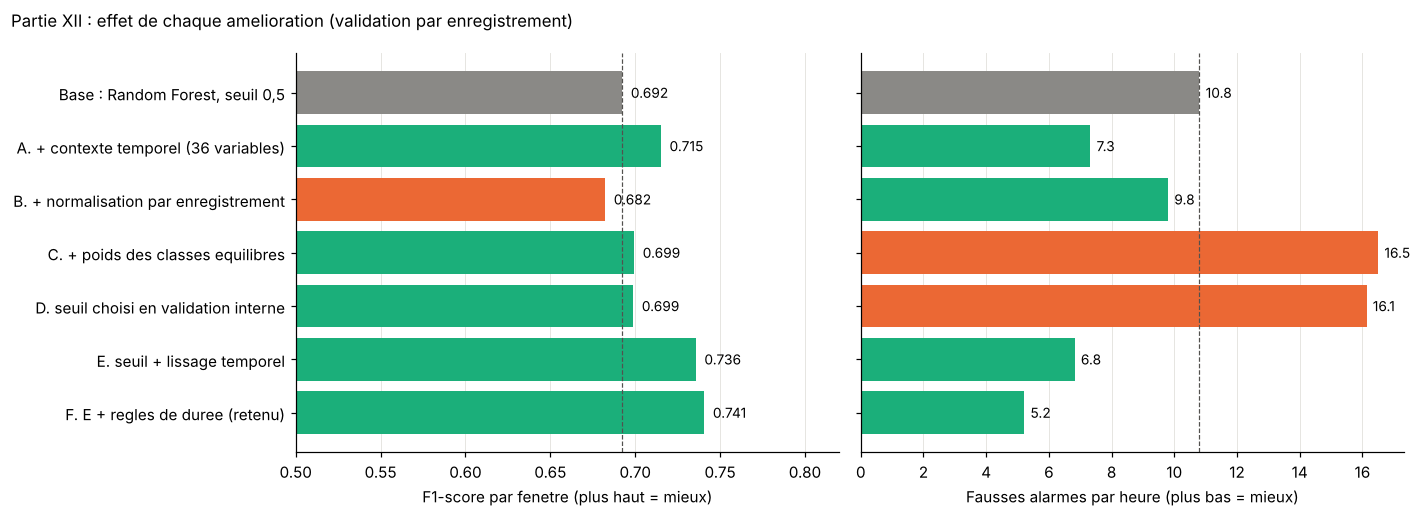

In [63]:
import time
from sklearn.base import clone

variants = {}
y_all = dataset["Class"]

# A. Caracteristiques de contexte (moyenne des fenetres voisines)
ctx_data, ctx_features = add_context_features(dataset, FEATURES)
start = time.perf_counter()
variants["A. + contexte temporel (36 variables)"] = (plain_predictions(best_estimator, ctx_data[ctx_features], y_all, groups) >= 0.5).astype(int)

# B. Normalisation par enregistrement + puissances relatives
norm_data, norm_features = add_recording_normalization(dataset, FEATURES)
variants["B. + normalisation par enregistrement"] = (plain_predictions(best_estimator, norm_data[norm_features], y_all, groups) >= 0.5).astype(int)

# C. Desequilibre : chaque arbre reequilibre les classes
balanced = clone(best_estimator).set_params(class_weight="balanced_subsample", min_samples_leaf=3)
variants["C. + poids des classes equilibres"] = (plain_predictions(balanced, dataset[FEATURES], y_all, groups) >= 0.5).astype(int)
print(f"Variantes A, B, C : {time.perf_counter() - start:.0f} s")

rows = {
    "Base : Random Forest, seuil 0,5": window_and_event_metrics(windows_pred, windows_pred["pred"], annotations),
    **{name: window_and_event_metrics(windows_pred, pred, annotations) for name, pred in variants.items()},
    "D. seuil choisi en validation interne": window_and_event_metrics(windows_pred, nested[1]["pred"], annotations),
    "E. seuil + lissage temporel": window_and_event_metrics(windows_pred, nested[3]["pred"], annotations),
    "F. E + regles de duree (retenu)": window_and_event_metrics(
        windows_pred, postprocess(nested[3]["pred"], groups, max_gap=1, min_windows=2), annotations),
}
improvements = pd.DataFrame(rows).T
display(improvements.style.format({"Accuracy": "{:.3f}", "Precision": "{:.3f}", "Recall": "{:.3f}", "F1-score": "{:.3f}"}))

fig = plot_improvements(improvements, "Base : Random Forest, seuil 0,5")
save("q16_2_ameliorations")

**Lecture**

* **Ce qui marche : seuil + lissage + règles de durée (F).** Le F1 passe de **0,69 à 0,74**, le
  Recall de 0,64 à 0,74, pour une Precision presque inchangée (0,76 → 0,74). Surtout, les
  **fausses alarmes sont divisées par 2** (10,8 → 5,2 par heure) tout en gardant **81 crises sur 83**.
* Le seuil seul (D) gagne du Recall mais crée beaucoup de fausses alarmes (16 par heure) :
  il ne sert qu'avec le lissage.
* Le **contexte temporel (A)** améliore le F1 (0,72) et réduit les fausses alarmes (7,3 par heure),
  mais perd 3 crises courtes : la moyenne sur 5 fenêtres dilue une crise de 2 à 3 s. C'est la même
  idée que le lissage (regarder les voisines), en entrée du modèle ; le lissage fait mieux, plus simplement.
* La **normalisation par enregistrement (B)** dégrade légèrement le résultat (F1 0,68). L'amplitude *absolue* est
  une information utile : une crise reste plus ample que l'activité normale de tous les patients.
  En divisant par la médiane de l'enregistrement, on perd cette information, et les
  enregistrements riches en crises ont une médiane déjà élevée. Piste rejetée.
* Le **rééquilibrage des classes (C)** ne change presque pas le F1 (0,70) et multiplie les fausses
  alarmes par 1,5 (16,5 par heure) : déplacer le seuil fait la même chose de façon plus contrôlée.

### Résultat final sur l'enregistrement de démonstration

230102B_F_0000 : crises detectees apres amelioration (seuil + lissage + regles de duree)


,Debut (s),Fin (s),Duree (s)
Crise detectee,,,
1,0.5,2.5,2.0
2,14.5,17.5,3.0
3,58.5,67.5,9.0
4,230.5,246.5,16.0
5,275.5,284.5,9.0
6,338.5,341.5,3.0
7,373.5,386.5,13.0
8,454.5,463.5,9.0
9,642.5,661.5,19.0


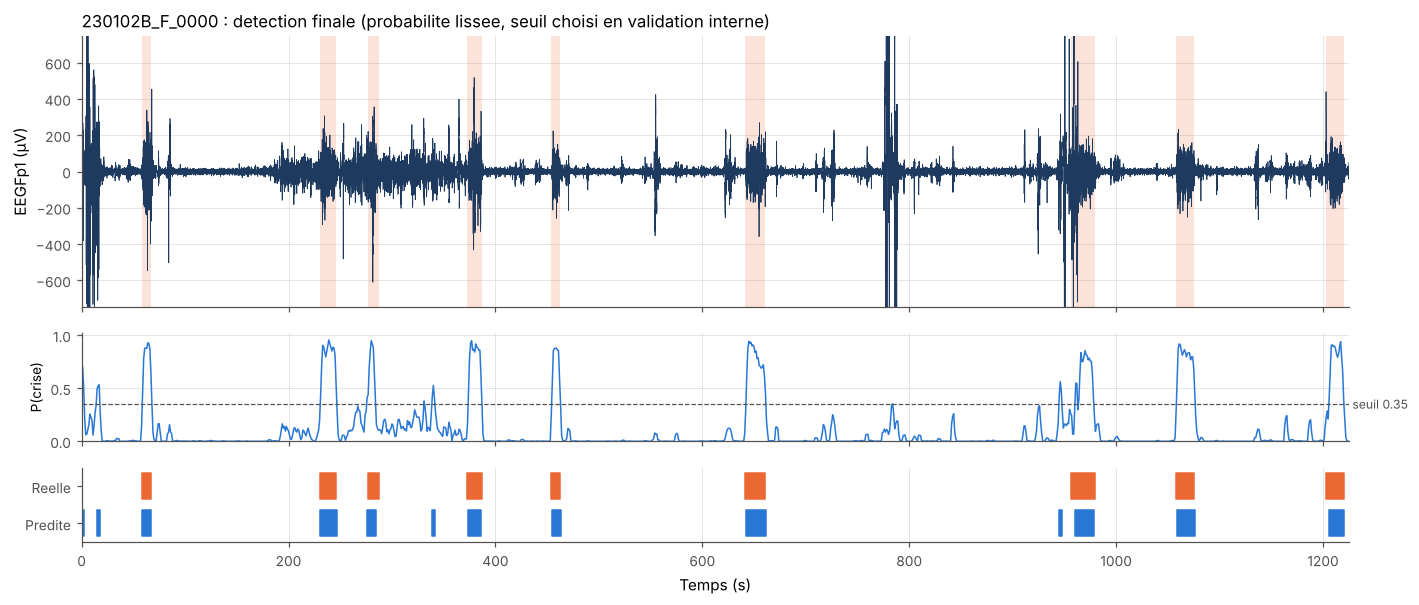

,crises reelles,crises detectees,intervalles predits,fausses alarmes,duree (h),retard median (s),sensibilite (%),fausses alarmes / h
enregistrement,,,,,,,,
TOTAL,83.0,81.0,132.0,42.0,8.08,NaN,97.6,5.2


In [64]:
windows_pred["pred_final"] = postprocess(nested[3]["pred"], groups, max_gap=1, min_windows=2)
intervals_final = detected_intervals(windows_pred, "pred_final")[RECORDING_ID]

print(f"{RECORDING_ID} : crises detectees apres amelioration (seuil + lissage + regles de duree)")
display(interval_table(intervals_final))

smoothed_demo = smooth_proba(demo_part["proba"].to_numpy(), np.zeros(len(demo_part)), 3)
fig = plot_detection(clean, "EEGFp1", true_demo, intervals_final,
                     proba=smoothed_demo, proba_time=demo_part["start_s"].to_numpy() + 1,
                     threshold=float(np.median(nested[3]["thresholds"])),
                     title=f"{RECORDING_ID} : detection finale (probabilite lissee, seuil choisi en validation interne)")
save("q16_3_detection_finale")

events_final = event_summary(windows_pred, "pred_final", annotations)
display(events_final.loc[["TOTAL"]])

* Sur `230102B_F`, les 9 crises restent détectées, la crise 7 n'est plus découpée en morceaux,
  les fausses alarmes d'une seconde ont disparu et il en reste 4 au lieu de 8 (de 2 à 3 s).
* Sur les 19 enregistrements : **81 crises sur 83 détectées, 5,2 fausses alarmes par heure**
  (contre 10,8 avant), retard au début de l'ordre de la seconde.

**Autres pistes, non testées ici** : fenêtres plus courtes (1 s) pour mieux placer le début de
crise ; variables qui décrivent la *forme* du signal (rythmicité à 3 Hz, autocorrélation,
nombre de pointes) pour séparer crises et artefacts ; apprentissage profond (CNN 1D sur le signal
brut des 19 canaux), qui demanderait plus d'enregistrements.

## Synthèse

| Étape | Résultat |
| --- | --- |
| Données | 19 enregistrements annotés, 83 crises, 8,1 h de signal à 256 Hz |
| Annotations | heures converties avec `DebutTrace` ; 2 doublons et 1 faute de saisie traités ; alignement vérifié sur chaque crise |
| Classes | 3,8 % des échantillons et 4,1 % des fenêtres en crise : fort déséquilibre |
| Dataset | 28 994 fenêtres de 2 s (recouvrement 50 %), 12 caractéristiques (8 temporelles, 4 bandes FFT) |
| Variables | très redondantes (Std = RMS, Variance = Energy) ; les plus discriminantes : Amplitude, Theta, Std ; Mean est inutile |
| Arbre de décision | Gini et entropie équivalents (F1 ≈ 0,73) ; Gini retenu car deux fois plus petit |
| Meilleur modèle (test 80/20) | **Random Forest : F1 = 0,79, Precision = 0,87, Recall = 0,72** |
| Modèle proposé | Gradient Boosting, deuxième (F1 = 0,76), le plus rapide parmi les meilleurs |
| Nouveau patient | F1 ≈ 0,70 (KNN, SVM, forêt) : c'est la performance à annoncer |
| Métrique (Q13) | accuracy trompeuse (95,9 % pour « toujours 0 ») ; Recall prioritaire, contrôlé par le F1 |
| Détection temporelle (Q14) | 81 crises sur 83 détectées, retard au début ≈ 1 s, mais 10,8 fausses alarmes par heure |
| Erreurs | FN au bord des crises et chez 2 patients ; FP isolés, loin des crises, sur 2 enregistrements à artefacts |
| Amélioration retenue | seuil choisi en validation interne + lissage + règles de durée : **F1 0,69 → 0,74, fausses alarmes 10,8 → 5,2 par heure** |
| Pistes rejetées | normalisation par enregistrement (F1 en baisse), rééquilibrage des classes (fausses alarmes ×1,5) |